# Workstation Rental Price Tier Prediction

**MLP Project, IIT Madras BS, Term 2026 T3**

| | |
|---|---|
| Competition | `workstation-rental-price-tier-prediction` (Kaggle) |
| Task | Predict `price_tier` (1 = cheapest … 4 = most expensive) of a workstation rental space |
| Type | Multi-class (4 classes, ordinal) classification |
| Metric | **Macro-averaged F1** (mean of the per-class F1 scores; every tier counts equally) |
| Pass cut-off | Leaderboard macro-F1 > 0.70 |

**Notebook flow:** EDA → preprocessing pipelines → feature engineering → model building
(linear, non-tree, tree, bagging, boosting, voting/stacking) → hyperparameter tuning →
before/after comparison → error analysis → final model and submission.

All figures are saved to `figures/` and all score tables to `results/`.
The Milestone 4 report uses them directly. Figure names follow the report's numbering
(`Q2.1`, `Q9.1`, …).

## 0. Setup

In [1]:
import glob
import json
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import lightgbm as lgb
import xgboost as xgb
import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, VotingClassifier
from sklearn.experimental import enable_halving_search_cv  # noqa: F401  (enables HalvingRandomSearchCV)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             f1_score)
from sklearn.model_selection import (GridSearchCV, HalvingRandomSearchCV, KFold,
                                     RandomizedSearchCV, StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder, OrdinalEncoder,
                                   StandardScaler, TargetEncoder)
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', context='notebook')

SEED = 42
N_JOBS = 4            # Kaggle CPU sessions have 4 cores; no accelerators are used
SCORING = 'f1_macro'  # the competition metric
np.random.seed(SEED)

print('sklearn', sklearn.__version__, '| lightgbm', lgb.__version__, '| xgboost', xgb.__version__)

sklearn 1.9.1 | lightgbm 4.7.0 | xgboost 3.4.1


In [2]:
# Locate the data: Kaggle mounts competition files under /kaggle/input; locally they live in data/.
def find_data_dir():
    hits = glob.glob('/kaggle/input/**/train.csv', recursive=True)
    if hits:
        return os.path.dirname(hits[0])
    for d in ['data', '../data', '../../data']:
        if os.path.exists(os.path.join(d, 'train.csv')):
            return d
    raise FileNotFoundError('train.csv not found')

DATA_DIR = find_data_dir()
OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else '.'
FIG_DIR = os.path.join(OUT_DIR, 'figures')
RES_DIR = os.path.join(OUT_DIR, 'results')
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

def savefig(name):
    """Save the current figure under figures/ with a report-friendly name."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'{name}.png'), dpi=120, bbox_inches='tight')
    plt.show()

train_raw = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'), low_memory=False)
test_raw = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'), low_memory=False)
TARGET, ID = 'price_tier', 'space_id'
print('data dir:', DATA_DIR)
print('train', train_raw.shape, '| test', test_raw.shape)
train_raw.head(3)

data dir: ../data
train (279746, 60) | test (114538, 59)


,space_id,operator_ref,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_class,operator_certified,operator_portfolio_size,operator_has_avatar,operator_id_verified,zone,borough,geo_lat,geo_lon,space_class,access_type,max_seats,utility_rooms,zones,workstations,facilities,snapshot_start_date,snapshot_end_date,min_term_days,max_term_days,min_term_floor,min_term_ceiling,max_term_floor,max_term_ceiling,min_term_avg,max_term_avg,bookable,open_slots_a,open_slots_b,open_slots_c,open_slots_d,review_count,review_count_12m,review_count_30d,open_slots_e,review_count_prev_yr,booked_load,first_review_date,last_review_date,score_overall,score_accuracy,score_condition,score_onboarding,score_support,score_access,score_value,compliance_status,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,metro,price_tier
0,0,Bralchu,12.0,8.0,7.0,8.0,independent_operator,f,2.0,t,t,ZN-0557,NaN,111.7005,-31.1170,Boutique Workroom,private_zone,2,1.0,NaN,1.0,"[""FCL-087"", ""FCL-007"", ""FCL-085"", ""FCL-072"", ""...",2024-08-20,2024-08-22,2.0,31.0,2.0,2.0,31.0,31.0,2.0,31.0,t,23,53,83,173,39,2,0,173,2,18,2016-11-03,2023-08-18,9.44,9.74,9.54,9.7,9.74,9.12,9.54,unlicensed,2,0,2,0,0.42,MTR-09,2
1,1,Grorfian,2.0,2.0,2.0,2.0,independent_operator,f,3.0,t,t,ZN-0082,BRG-18,88.0215,-123.2818,Boutique Workroom,private_zone,1,2.0,1.0,1.0,"[""FCL-135"", ""FCL-136"", ""FCL-141"", ""FCL-077"", ""...",2024-08-24,2024-09-24,30.0,120.0,30.0,30.0,120.0,120.0,30.0,120.0,t,15,45,75,75,0,0,0,75,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unlicensed,3,1,2,0,NaN,MTR-01,1
2,2,Snelenr,10.0,10.0,7.0,10.0,independent_operator,f,1.0,t,t,ZN-0082,BRG-18,88.0350,-123.2662,Ground Bay,whole_unit,2,1.0,1.0,1.0,"[""FCL-019"", ""FCL-136"", ""FCL-135"", ""FCL-043"", ""...",2024-08-09,2024-09-09,30.0,1125.0,30.0,30.0,1125.0,1125.0,30.0,1125.0,t,30,60,90,270,2,0,0,199,0,0,2019-09-02,2021-07-25,10.00,10.00,10.00,10.0,10.00,10.00,10.00,unlicensed,1,1,0,0,0.03,MTR-01,2


## 1. Exploratory Data Analysis
### 1.1 Structure, data types and missing values

In [3]:
print('Columns only in train:', set(train_raw.columns) - set(test_raw.columns))
overview = pd.DataFrame({
    'dtype': train_raw.dtypes.astype(str),
    'n_unique': train_raw.nunique(),
    'missing_train_%': (train_raw.isna().mean() * 100).round(1),
    'missing_test_%': (test_raw.isna().mean() * 100).round(1),
})
overview.sort_values('missing_train_%', ascending=False)

Columns only in train: {'price_tier'}


,dtype,n_unique,missing_train_%,missing_test_%
borough,str,55,76.7,75.1
first_review_date,str,5342,19.4,18.7
last_review_date,str,3287,19.4,18.7
score_value,float64,202,19.4,18.7
reviews_per_month,float64,1435,19.4,18.7
score_access,float64,186,19.4,18.7
score_accuracy,float64,194,19.4,18.7
score_condition,float64,213,19.4,18.7
score_onboarding,float64,185,19.4,18.7
score_overall,float64,204,19.4,18.7


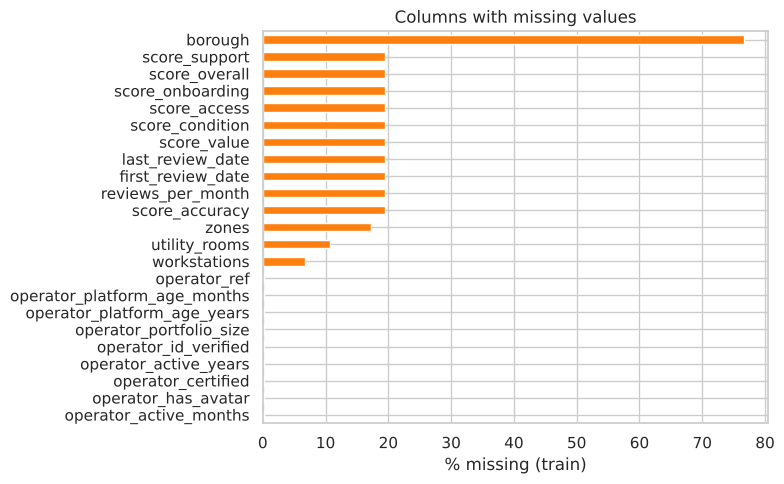

In [4]:
miss = overview['missing_train_%'][overview['missing_train_%'] > 0].sort_values()
plt.figure(figsize=(8, 5))
miss.plot.barh(color='tab:orange')
plt.xlabel('% missing (train)')
plt.title('Columns with missing values')
savefig('eda_missing_values')

**Observations**
* `borough` is ~77% missing, so it is kept with an explicit `missing` category.
* All review columns (`score_*`, `reviews_per_month`, `first/last_review_date`) are missing for the
  **same 19.4% of rows**: spaces that have never been reviewed. The missingness carries
  information, so a `has_reviews` flag is added and imputers use `add_indicator=True` for linear models.
* `zones` (17%), `utility_rooms` (11%) and `workstations` (7%) are missing at random-looking rates
  and are imputed with the median.
* Missing rates in test match train, so the same pipeline can be applied to both.

### 1.2 Target distribution

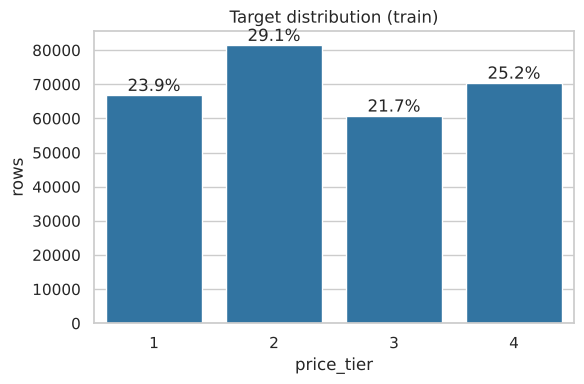

In [5]:
tier_counts = train_raw[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=tier_counts.index, y=tier_counts.values, ax=ax, color='tab:blue')
for i, v in enumerate(tier_counts.values):
    ax.text(i, v, f'{v / len(train_raw):.1%}', ha='center', va='bottom')
ax.set(xlabel='price_tier', ylabel='rows', title='Target distribution (train)')
savefig('eda_target_distribution')

The four tiers are fairly balanced (22–29%). Accuracy and macro-F1 will be close, but
macro-F1 still rewards getting the smaller tiers (1 and 3) right. **Stratified** splits keep
these proportions in every fold.

### 1.3 Univariate analysis: numerical features

In [6]:
num_cols_raw = train_raw.select_dtypes('number').columns.drop([ID, TARGET])
desc = train_raw[num_cols_raw].describe().T
desc['skew'] = train_raw[num_cols_raw].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
operator_platform_age_years,279142.0,6.79,4.19,0.00,3.00,7.00,10.00,1.700000e+01,-0.04
operator_platform_age_months,279142.0,5.45,3.49,0.00,2.00,5.00,9.00,1.100000e+01,0.02
operator_active_years,279140.0,5.08,4.04,0.00,2.00,4.00,8.00,1.500000e+01,0.52
operator_active_months,279140.0,5.30,3.48,0.00,2.00,5.00,8.00,1.100000e+01,0.07
operator_portfolio_size,279142.0,49.47,332.75,0.00,1.00,4.00,19.00,5.978000e+03,16.08
geo_lat,279746.0,77.77,37.51,-4.82,68.04,94.62,100.94,1.117700e+02,-1.23
geo_lon,279746.0,-35.14,57.17,-123.75,-76.56,-31.13,-21.27,8.705000e+01,0.56
max_seats,279746.0,3.63,2.28,1.00,2.00,3.00,4.00,1.600000e+01,1.96
utility_rooms,249847.0,1.36,0.81,0.50,1.00,1.00,1.50,5.000000e+01,7.38
zones,231332.0,1.66,1.09,0.00,1.00,1.00,2.00,5.000000e+01,6.68


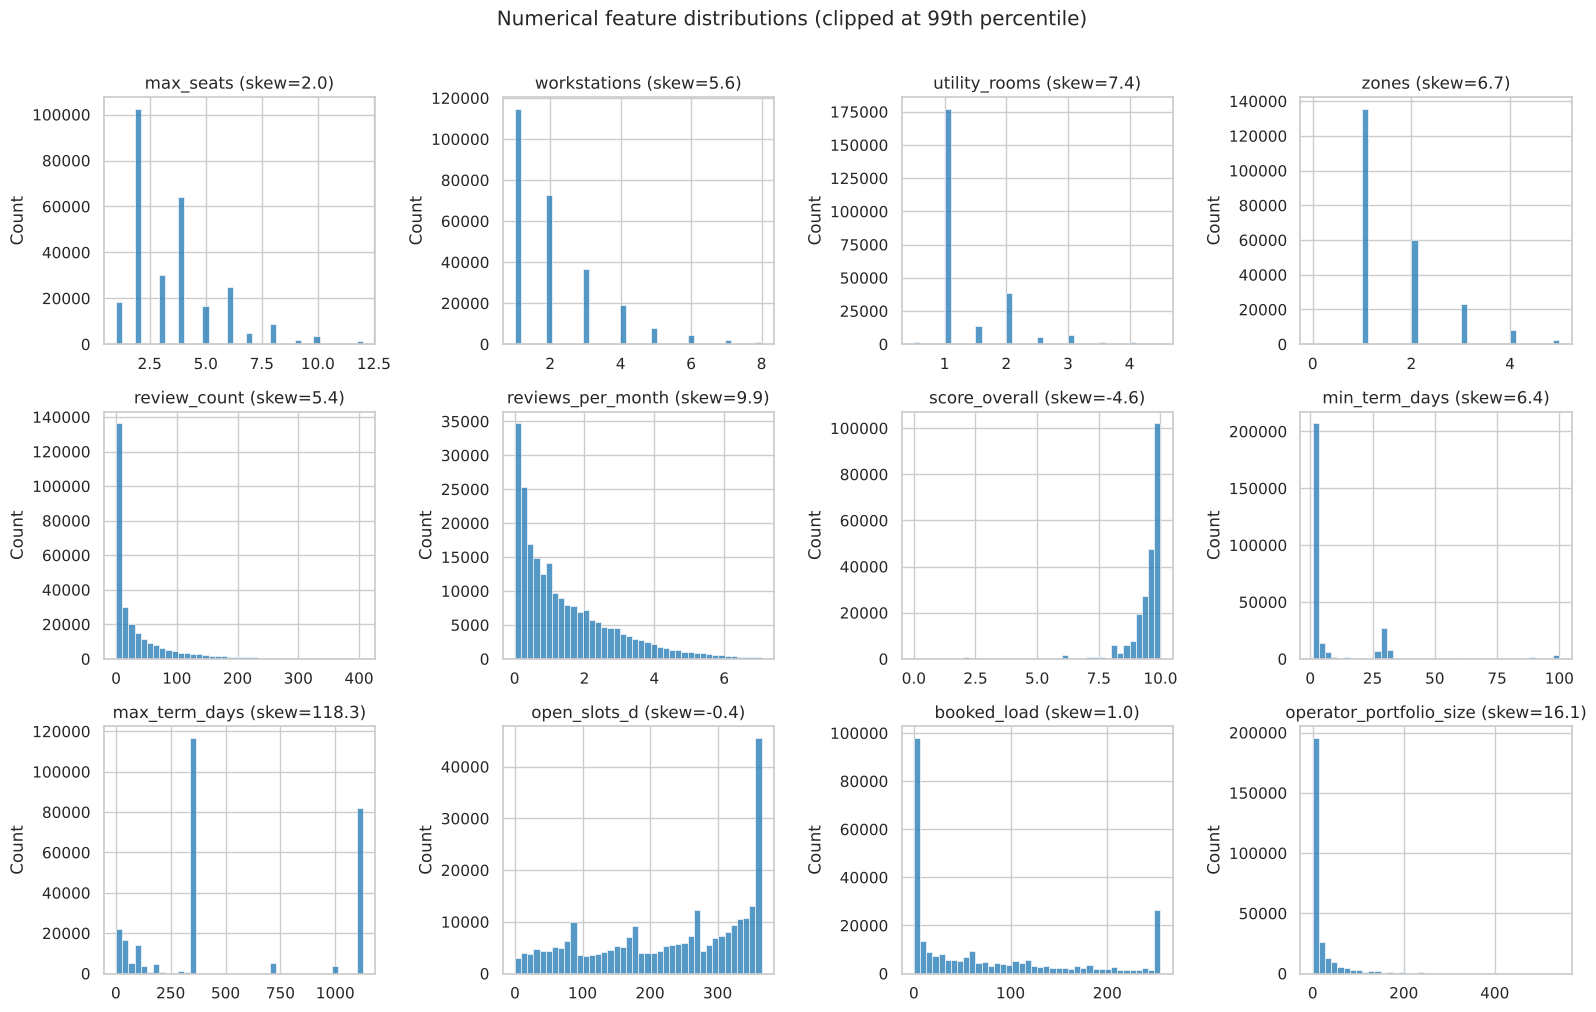

In [7]:
show = ['max_seats', 'workstations', 'utility_rooms', 'zones', 'review_count', 'reviews_per_month',
        'score_overall', 'min_term_days', 'max_term_days', 'open_slots_d', 'booked_load',
        'operator_portfolio_size']
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.ravel(), show):
    data = train_raw[c].dropna()
    hi = data.quantile(0.99)
    sns.histplot(data[data <= hi], bins=40, ax=ax, color='tab:blue')
    ax.set_title(f'{c} (skew={data.skew():.1f})')
    ax.set_xlabel('')
plt.suptitle('Numerical feature distributions (clipped at 99th percentile)', y=1.01)
savefig('eda_numeric_distributions')

Many count-like features (`review_count`, `operator_portfolio_size`, `max_term_days`, …) are strongly
right-skewed with long tails. Tree models do not care, but for distance- and gradient-based models
(logistic regression, KNN) a `log1p` transform followed by standardisation is applied.

### 1.4 Univariate analysis: categorical features

In [8]:
cat_cols_raw = train_raw.select_dtypes(exclude='number').columns
pd.DataFrame({'n_unique': train_raw[cat_cols_raw].nunique(),
              'top_value': train_raw[cat_cols_raw].mode().iloc[0],
              'top_share_%': [round(train_raw[c].value_counts(normalize=True).iloc[0] * 100, 1)
                              for c in cat_cols_raw]}).sort_values('n_unique')

,n_unique,top_value,top_share_%
operator_has_avatar,2,t,95.8
operator_certified,2,f,64.6
operator_id_verified,2,t,98.6
bookable,2,t,99.3
operator_class,3,unverified_operator,45.6
access_type,4,whole_unit,75.4
compliance_status,4,unlicensed,55.3
metro,16,MTR-09,12.8
borough,55,BRG-18,16.3
space_class,131,Ground Bay,54.1


* Low cardinality (one-hot friendly): `operator_class` (3), `access_type` (4), `compliance_status` (4),
  `metro` (16), plus the t/f flags.
* High cardinality: `zone` (1,380), `space_class` (131), `borough` (55). One-hot would add ~1,500 sparse
  columns, so these are **target-encoded** (cross-fitted inside the pipeline to avoid leakage).
* `operator_ref` (41,903 hosts) is an identifier. It is replaced by how many listings each operator has.
* `facilities` is a JSON list of amenity codes and is parsed into a count plus one binary column per code.
* Date columns are converted into "days since" numbers.

### 1.5 Bivariate analysis: features vs target

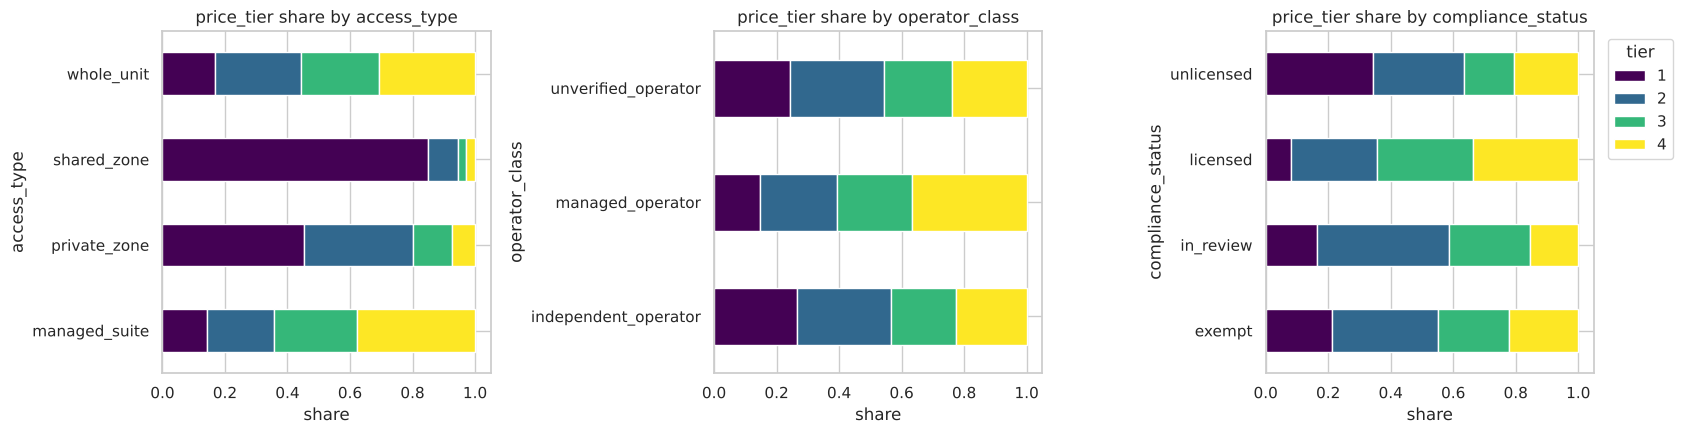

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, c in zip(axes, ['access_type', 'operator_class', 'compliance_status']):
    ct = pd.crosstab(train_raw[c], train_raw[TARGET], normalize='index')
    ct.plot.barh(stacked=True, ax=ax, colormap='viridis', legend=(c == 'compliance_status'))
    ax.set_title(f'price_tier share by {c}')
    ax.set_xlabel('share')
axes[-1].legend(title='tier', bbox_to_anchor=(1.02, 1), loc='upper left')
savefig('eda_categorical_vs_target')

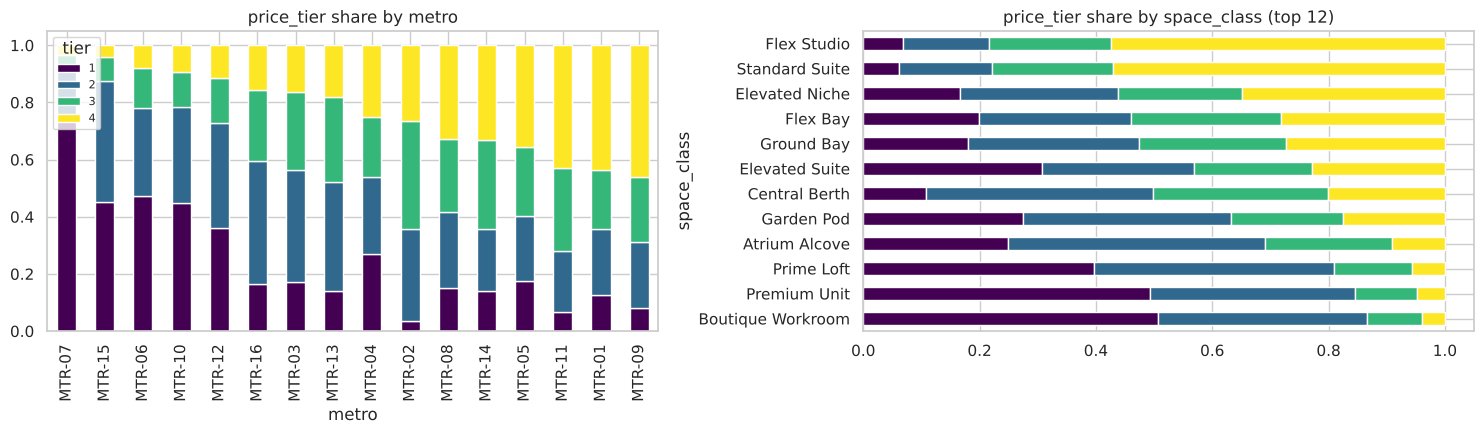

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ct = pd.crosstab(train_raw['metro'], train_raw[TARGET], normalize='index').sort_values(4)
ct.plot.bar(stacked=True, ax=axes[0], colormap='viridis')
axes[0].set_title('price_tier share by metro')
axes[0].legend(title='tier', loc='upper left', fontsize=8)
top_sc = train_raw['space_class'].value_counts().index[:12]
ct = pd.crosstab(train_raw.loc[train_raw.space_class.isin(top_sc), 'space_class'],
                 train_raw[TARGET], normalize='index').sort_values(4)
ct.plot.barh(stacked=True, ax=axes[1], colormap='viridis', legend=False)
axes[1].set_title('price_tier share by space_class (top 12)')
savefig('eda_metro_spaceclass_vs_target')

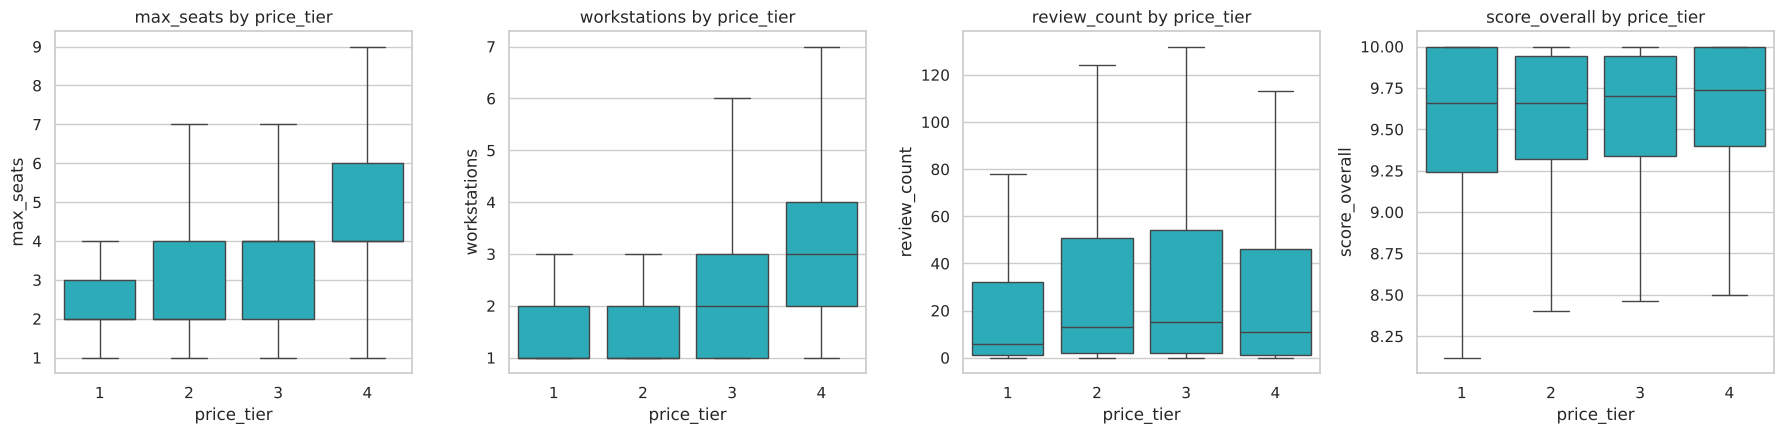

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, c in zip(axes, ['max_seats', 'workstations', 'review_count', 'score_overall']):
    data = train_raw[[c, TARGET]].dropna()
    data = data[data[c] <= data[c].quantile(0.99)]
    sns.boxplot(data=data, x=TARGET, y=c, ax=ax, showfliers=False, color='tab:cyan')
    ax.set_title(f'{c} by price_tier')
savefig('eda_numeric_vs_target')

**Observations**
* **Capacity drives price.** Median `max_seats` is 2 / 2 / 4 / 5 for tiers 1–4, and `workstations`
  rises in the same way. Capacity separates {1, 2} from {3, 4} but not 1 from 2.
* **Access type matters.** 85% of `shared_zone` spaces are tier 1 and only 7% of `private_zone`
  spaces are tier 4, while whole units are spread across all tiers.
* **Location matters.** Tier mix differs strongly between metros, so `metro`, `zone` and
  coordinates are key to telling the cheaper tiers apart.
* Review scores barely move with tier. They are weak on their own.

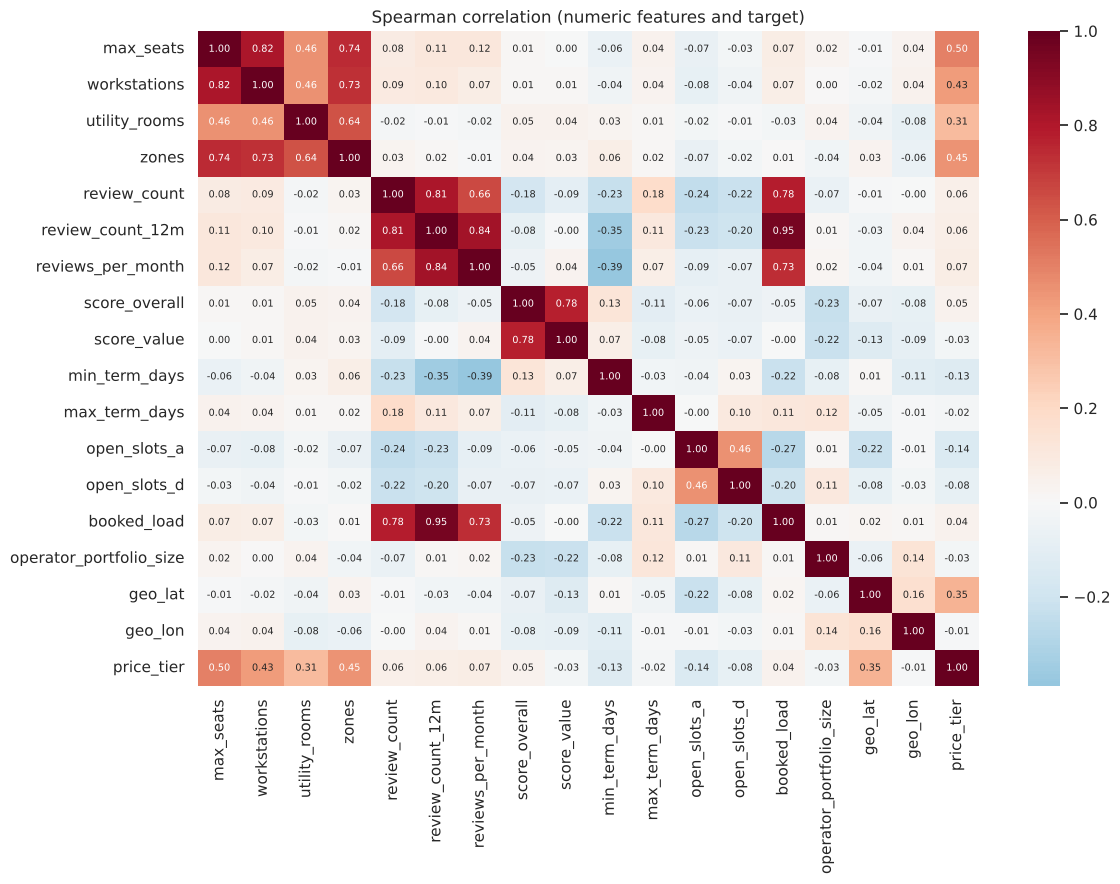

In [12]:
corr_cols = ['max_seats', 'workstations', 'utility_rooms', 'zones', 'review_count', 'review_count_12m',
             'reviews_per_month', 'score_overall', 'score_value', 'min_term_days', 'max_term_days',
             'open_slots_a', 'open_slots_d', 'booked_load', 'operator_portfolio_size', 'geo_lat',
             'geo_lon', TARGET]
plt.figure(figsize=(12, 9))
sns.heatmap(train_raw[corr_cols].corr(method='spearman'), cmap='RdBu_r', center=0, annot=True,
            fmt='.2f', annot_kws={'size': 7})
plt.title('Spearman correlation (numeric features and target)')
savefig('eda_correlation_heatmap')

* `max_seats`, `workstations`, `utility_rooms` and `zones` are inter-correlated (all measure size)
  and are the numeric features most correlated with the tier.
* Groups of near-duplicate features exist (`open_slots_a…e`, `min_term_*`, `max_term_*`,
  `review_count*`). Regularisation (linear models) and feature subsampling (forests and boosting)
  handle this redundancy.

distinct facility codes: 144


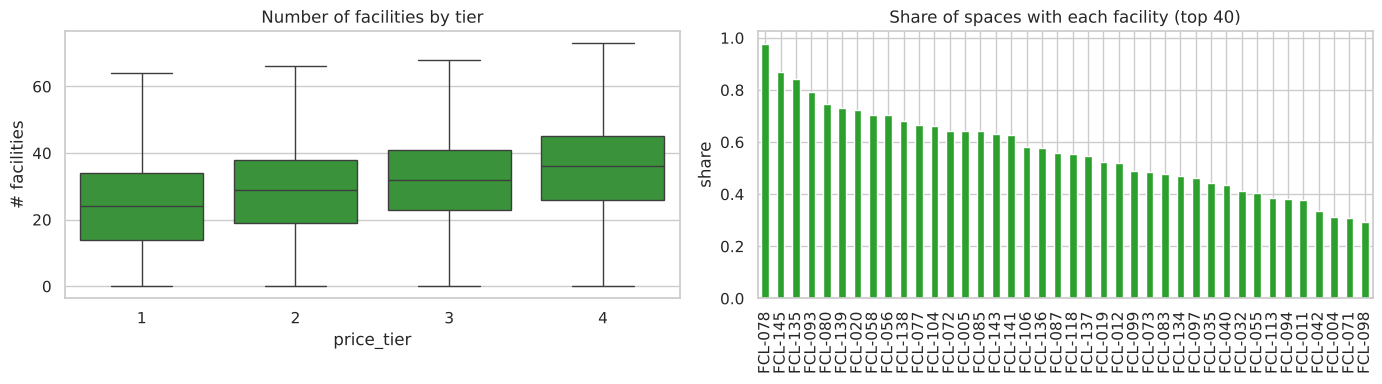

In [13]:
fac_lists = train_raw['facilities'].map(json.loads)
fac_vocab = pd.Series([c for lst in fac_lists for c in lst]).value_counts()
print('distinct facility codes:', len(fac_vocab))
fac_n = fac_lists.map(len)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=train_raw[TARGET], y=fac_n, ax=axes[0], showfliers=False, color='tab:green')
axes[0].set(title='Number of facilities by tier', ylabel='# facilities')
(fac_vocab / len(train_raw)).head(40).plot.bar(ax=axes[1], color='tab:green')
axes[1].set(title='Share of spaces with each facility (top 40)', ylabel='share')
savefig('eda_facilities')

Higher tiers list more facilities. The 144 codes become binary indicators, and codes present
in fewer than 0.5% of spaces are dropped as too rare to learn from.

## 2. Preprocessing and Feature Engineering

Two layers, both reusable and applied identically to train and test:

1. **`build_features()`**: stateless, row-wise transformations (parsing, date arithmetic,
   ratios, facility indicators). They learn nothing from data, so it is safe to apply them once
   to train and test. The facility vocabulary is taken from train only.
2. **sklearn `ColumnTransformer` pipelines**: everything that *learns* from data (imputation
   medians, scaling, target and frequency encoding). They live inside each model's `Pipeline`,
   so they are re-fitted on the training folds only during cross-validation, with no leakage.

In [14]:
BINARY_COLS = ['operator_certified', 'operator_has_avatar', 'operator_id_verified', 'bookable']
FAC_VOCAB = sorted(fac_vocab[fac_vocab / len(train_raw) >= 0.005].index)  # from train only


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """Stateless feature engineering shared by train and test."""
    X = df.copy()
    for c in BINARY_COLS:                                   # t/f -> 1/0 (NaN stays NaN)
        X[c] = X[c].map({'t': 1, 'f': 0}).astype(float)
    # tenure was split into years + months: merge into total months
    X['operator_platform_age'] = X['operator_platform_age_years'] * 12 + X['operator_platform_age_months']
    X['operator_active_age'] = X['operator_active_years'] * 12 + X['operator_active_months']
    # dates -> numbers relative to the snapshot date
    end = pd.to_datetime(X['snapshot_end_date'])
    X['days_since_first_review'] = (end - pd.to_datetime(X['first_review_date'])).dt.days
    X['days_since_last_review'] = (end - pd.to_datetime(X['last_review_date'])).dt.days
    X['snapshot_month'] = end.dt.year * 12 + end.dt.month
    X['has_reviews'] = X['first_review_date'].notna().astype(int)
    # size ratios
    X['seats_per_workstation'] = X['max_seats'] / X['workstations'].replace(0, np.nan)
    X['seats_per_zone'] = X['max_seats'] / X['zones'].replace(0, np.nan)
    X['booked_share'] = X['booked_load'] / (X['booked_load'] + X['open_slots_d'] + 1)
    # facilities: count + one indicator per (non-rare) code
    fac = X['facilities'].map(json.loads).map(set)
    X['n_facilities'] = fac.map(len)
    fac_df = pd.DataFrame({f'fac_{c}': fac.map(lambda s, c=c: int(c in s)) for c in FAC_VOCAB},
                          index=X.index, dtype='int8')
    X['borough'] = X['borough'].fillna('missing')
    X['operator_ref'] = X['operator_ref'].fillna('missing')
    drop = [ID, TARGET, 'facilities', 'first_review_date', 'last_review_date', 'snapshot_start_date',
            'snapshot_end_date', 'operator_platform_age_years', 'operator_platform_age_months',
            'operator_active_years', 'operator_active_months']
    return pd.concat([X.drop(columns=[c for c in drop if c in X.columns]), fac_df], axis=1)


class FrequencyEncoder(BaseEstimator, TransformerMixin):
    """Replace each category by how often it occurs in the training data (unseen -> 0)."""
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.maps_ = {c: X[c].value_counts() for c in X.columns}
        self.columns_ = list(X.columns)
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.columns_)
        return np.column_stack([X[c].map(self.maps_[c]).fillna(0).to_numpy(float) for c in self.columns_])

    def get_feature_names_out(self, input_features=None):
        return np.array([f'{c}_freq' for c in self.columns_])


t0 = time.time()
X_full = build_features(train_raw)
y_full = train_raw[TARGET].copy()
X_test = build_features(test_raw)
assert list(X_full.columns) == list(X_test.columns)
print(f'built features in {time.time() - t0:.0f}s ->', X_full.shape, X_test.shape)

built features in 20s -> (279746, 193) (114538, 193)


In [15]:
HIGH_CARD = ['zone', 'space_class', 'borough']                          # target-encoded
LOW_CARD = ['operator_class', 'access_type', 'compliance_status', 'metro']  # one-hot / ordinal
FREQ_COLS = ['zone', 'operator_ref']                                    # frequency-encoded
NUM_COLS = [c for c in X_full.columns if c not in HIGH_CARD + LOW_CARD + ['operator_ref']]
FAC_COLS = [c for c in NUM_COLS if c.startswith('fac_')]
SKEWED = [c for c in NUM_COLS if c not in FAC_COLS and X_full[c].min() >= 0 and X_full[c].skew() > 2]
PLAIN = [c for c in NUM_COLS if c not in SKEWED]
print(f'{len(NUM_COLS)} numeric ({len(FAC_COLS)} facility flags, {len(SKEWED)} skewed) | '
      f'{len(HIGH_CARD)} high-card | {len(LOW_CARD)} low-card categorical')


def make_linear_preprocessor():
    """For scale-sensitive models (logistic regression, KNN)."""
    log_scale = Pipeline([('impute', SimpleImputer(strategy='median')),
                          ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                          ('scale', StandardScaler())])
    plain = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                      ('scale', StandardScaler())])
    return ColumnTransformer([
        ('target_enc', make_pipeline(TargetEncoder(random_state=SEED), StandardScaler()), HIGH_CARD),
        ('freq_enc', make_pipeline(FrequencyEncoder(), FunctionTransformer(np.log1p, feature_names_out='one-to-one'), StandardScaler()), FREQ_COLS),
        ('onehot', OneHotEncoder(handle_unknown='ignore'), LOW_CARD),
        ('log_num', log_scale, SKEWED),
        ('num', plain, PLAIN),
    ])


def make_tree_preprocessor(impute=True):
    """For tree models: no scaling or one-hot needed; ordinal codes for low-card categoricals."""
    num = SimpleImputer(strategy='median') if impute else 'passthrough'
    return ColumnTransformer([
        ('target_enc', TargetEncoder(random_state=SEED), HIGH_CARD),
        ('freq_enc', FrequencyEncoder(), FREQ_COLS),
        ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), LOW_CARD),
        ('num', num, NUM_COLS),
    ])


lin_demo = make_linear_preprocessor().fit(X_full.head(20000), y_full.head(20000))
tree_demo = make_tree_preprocessor().fit(X_full.head(20000), y_full.head(20000))
print('linear preprocessor output columns:', lin_demo.transform(X_full.head(5)).shape[1])
print('tree preprocessor output columns  :', tree_demo.transform(X_full.head(5)).shape[1])

185 numeric (134 facility flags, 25 skewed) | 3 high-card | 4 low-card categorical


linear preprocessor output columns: 240
tree preprocessor output columns  : 203


**Why these choices**
* *Target encoding* replaces each `zone`/`space_class`/`borough` value with the per-tier mean of the
  target (one column per class). sklearn's `TargetEncoder` cross-fits internally, so a row's own label
  never leaks into its encoding.
* *Scaling* matters for logistic regression (regularisation strength and solver convergence) and for
  KNN (Euclidean distance). Trees split on thresholds, so the tree preprocessor skips it.
* *Imputation*: median for numeric features; linear models also get missing-indicator columns.
  LightGBM and XGBoost receive raw NaNs (`impute=False`) because they learn a default
  direction for missing values.

### 2.1 Validation design

* **Hold-out**: a stratified 80/20 split of `train.csv`. Every model is compared on the same 55,950
  held-out rows using macro-F1.
* **Tuning**: `StratifiedKFold(3)` on a 30,000-row stratified sample of the training part. This keeps
  searches affordable on a 4-core CPU, and the tuned configurations are then refitted on the full
  training part and scored on the hold-out.

In [16]:
X_tr, X_val, y_tr, y_val = train_test_split(X_full, y_full, test_size=0.2, stratify=y_full,
                                            random_state=SEED)
X_tune, _, y_tune, _ = train_test_split(X_tr, y_tr, train_size=30000, stratify=y_tr, random_state=SEED)
CV3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
print('train', X_tr.shape, '| hold-out', X_val.shape, '| tuning sample', X_tune.shape)

RESULTS = []  # one row per (model, stage)


def evaluate(name, model, stage, X_fit=None, y_fit=None, family=''):
    """Fit on the training part (or a given subset), score macro-F1 on hold-out, log the result."""
    X_fit = X_tr if X_fit is None else X_fit
    y_fit = y_tr if y_fit is None else y_fit
    t = time.time()
    model.fit(X_fit, y_fit)
    fit_s = time.time() - t
    pred = model.predict(X_val)
    row = dict(model=name, family=family, stage=stage, train_rows=len(X_fit),
               holdout_macro_f1=f1_score(y_val, pred, average='macro'),
               holdout_accuracy=(pred == y_val.to_numpy()).mean(), fit_seconds=round(fit_s, 1))
    RESULTS.append(row)
    print(f"{name:<28} {stage:<9} macro-F1={row['holdout_macro_f1']:.4f}  acc={row['holdout_accuracy']:.4f}  "
          f"fit={fit_s:.0f}s")
    return model

train (223796, 193) | hold-out (55950, 193) | tuning sample (30000, 193)


### 2.2 Does feature engineering help?
A quick ablation with the same LightGBM model: raw columns only (categoricals ordinal-encoded,
dates and facilities dropped) vs the engineered feature set.

In [17]:
def raw_only(df):
    X = df.drop(columns=[ID, TARGET, 'facilities', 'first_review_date', 'last_review_date',
                         'snapshot_start_date', 'snapshot_end_date', 'operator_ref'], errors='ignore').copy()
    for c in BINARY_COLS:
        X[c] = X[c].map({'t': 1, 'f': 0})
    return X

raw_cat = ['zone', 'space_class', 'borough'] + LOW_CARD
raw_pre = ColumnTransformer([('ord', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1,
                                                    encoded_missing_value=-1), raw_cat)],
                            remainder='passthrough')
quick_lgb = dict(n_estimators=400, learning_rate=0.1, num_leaves=63, colsample_bytree=0.5,
                 random_state=SEED, n_jobs=N_JOBS, verbose=-1)
abl = {}
m = make_pipeline(raw_pre, lgb.LGBMClassifier(**quick_lgb)).fit(raw_only(train_raw.loc[X_tr.index]), y_tr)
abl['raw columns'] = f1_score(y_val, m.predict(raw_only(train_raw.loc[X_val.index])), average='macro')
m = make_pipeline(make_tree_preprocessor(impute=False), lgb.LGBMClassifier(**quick_lgb)).fit(X_tr, y_tr)
abl['engineered features'] = f1_score(y_val, m.predict(X_val), average='macro')
fe_model = m
print(pd.Series(abl, name='hold-out macro-F1').round(4))

raw columns            0.7173
engineered features    0.7321
Name: hold-out macro-F1, dtype: float64


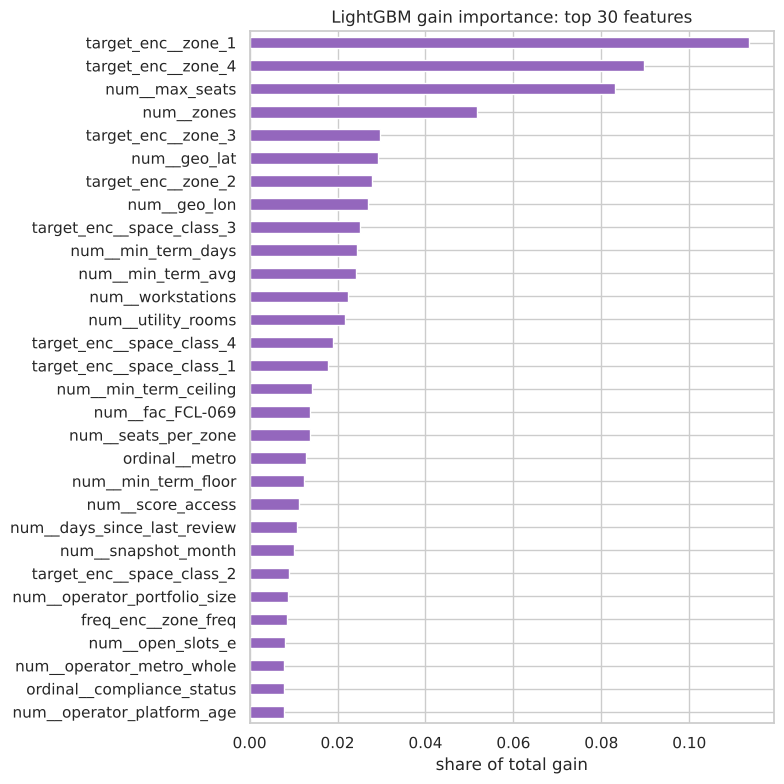

Importance rank of engineered features:
                             rank  gain_share_%
seats_per_zone                 18          1.38
days_since_last_review         22          1.07
snapshot_month                 23          1.00
freq_enc__zone_freq            26          0.86
operator_platform_age          30          0.78
n_facilities                   33          0.77
operator_active_age            34          0.75
seats_per_workstation          36          0.74
booked_share                   40          0.63
freq_enc__operator_ref_freq    41          0.63
days_since_first_review        43          0.59
has_reviews                   203          0.00
total gain share of facility flags: 8.3%


In [18]:
feat_names = fe_model[0].get_feature_names_out()
imp = pd.Series(fe_model[-1].booster_.feature_importance('gain'), index=feat_names)
imp = (imp / imp.sum()).sort_values(ascending=False)
plt.figure(figsize=(8, 8))
imp.head(30)[::-1].plot.barh(color='tab:purple')
plt.title('LightGBM gain importance: top 30 features')
plt.xlabel('share of total gain')
savefig('fe_feature_importance')
engineered = ['operator_platform_age', 'operator_active_age', 'days_since_first_review',
              'days_since_last_review', 'snapshot_month', 'has_reviews', 'seats_per_workstation',
              'seats_per_zone', 'booked_share', 'n_facilities', 'freq_enc__zone_freq',
              'freq_enc__operator_ref_freq']
imp_named = imp.rename(index=lambda s: s.split('__', 1)[1] if s.startswith(('num__',)) else s)
print('Importance rank of engineered features:')
ranks = imp_named.rank(ascending=False).astype(int)
print(pd.DataFrame({'rank': ranks.reindex(engineered), 'gain_share_%': (imp_named.reindex(engineered) * 100).round(2)})
      .sort_values('rank').to_string())
print('total gain share of facility flags: %.1f%%' % (imp_named[imp_named.index.str.startswith('fac_')].sum() * 100))

## 3. Model Building (Milestone 4)

| Family | Model | Why it fits this problem |
|---|---|---|
| Linear | Multinomial **Logistic Regression** | Fast, interpretable baseline; tells us how far linear boundaries get |
| Non-tree, non-linear | **K-Nearest Neighbours** | Local, similarity-based; spaces near each other in feature space (location, size) cost alike |
| Tree | **Decision Tree** | Captures thresholds and interactions (seats × access type × metro) without scaling |
| Bagging | **Random Forest** | Averages many decorrelated deep trees, so less variance than one tree |
| Boosting | **LightGBM**, **XGBoost** | Sequentially corrects errors; state of the art on tabular data of this size |
| Ensembles | **Soft Voting**, **Stacking** | Combine different model families whose errors differ |

**Step 1: baselines.** Every model is trained with (near-)default hyperparameters on the training
part and scored on the hold-out. KNN uses a 50k-row sample because prediction cost grows with
training-set size.

In [19]:
knn_idx = X_tr.sample(50000, random_state=SEED).index
LABELS = np.sort(y_full.unique())                 # [1, 2, 3, 4]


class EncodeLabels(ClassifierMixin, BaseEstimator):
    """XGBoost needs labels 0..K-1: encode on fit, decode on predict (tiers 1..4 stay visible outside)."""
    def __init__(self, estimator):
        self.estimator = estimator

    def fit(self, X, y):
        self.classes_, y_enc = np.unique(np.asarray(y), return_inverse=True)
        self.estimator_ = clone(self.estimator).fit(X, y_enc)
        return self

    def predict(self, X):
        return self.classes_[np.asarray(self.estimator_.predict(X)).astype(int).ravel()]

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)


baseline_models = {
    'Logistic Regression': ('linear', make_pipeline(make_linear_preprocessor(),
                                                    LogisticRegression(max_iter=1000))),
    'KNN (50k sample)': ('non-tree', make_pipeline(make_linear_preprocessor(),
                                                   KNeighborsClassifier(n_jobs=N_JOBS))),
    'Decision Tree': ('tree', make_pipeline(make_tree_preprocessor(),
                                            DecisionTreeClassifier(random_state=SEED))),
    'Random Forest': ('bagging', make_pipeline(make_tree_preprocessor(),
                                               RandomForestClassifier(n_estimators=100, n_jobs=N_JOBS,
                                                                      random_state=SEED))),
    'LightGBM': ('boosting', make_pipeline(make_tree_preprocessor(impute=False),
                                           lgb.LGBMClassifier(random_state=SEED, n_jobs=N_JOBS, verbose=-1))),
    'XGBoost': ('boosting', make_pipeline(make_tree_preprocessor(impute=False),
                                          EncodeLabels(xgb.XGBClassifier(tree_method='hist', random_state=SEED,
                                                                         n_jobs=N_JOBS)))),
}

fitted_baselines = {}
for name, (family, model) in baseline_models.items():
    if name.startswith('KNN'):
        fitted_baselines[name] = evaluate(name, model, 'baseline', X_tr.loc[knn_idx], y_tr.loc[knn_idx], family)
    else:
        fitted_baselines[name] = evaluate(name, model, 'baseline', family=family)

Logistic Regression          baseline  macro-F1=0.6597  acc=0.6670  fit=32s


KNN (50k sample)             baseline  macro-F1=0.5679  acc=0.5726  fit=1s


Decision Tree                baseline  macro-F1=0.6135  acc=0.6154  fit=18s


Random Forest                baseline  macro-F1=0.7191  acc=0.7244  fit=20s


LightGBM                     baseline  macro-F1=0.6980  acc=0.7030  fit=9s


XGBoost                      baseline  macro-F1=0.7149  acc=0.7194  fit=14s


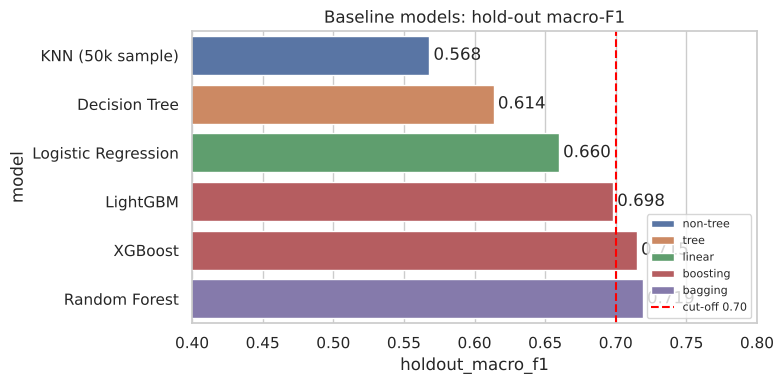

In [20]:
base_df = pd.DataFrame(RESULTS).query("stage == 'baseline'").sort_values('holdout_macro_f1')
plt.figure(figsize=(8, 4))
ax = sns.barplot(data=base_df, y='model', x='holdout_macro_f1', hue='family', dodge=False)
for i, v in enumerate(base_df['holdout_macro_f1']):
    ax.text(v + 0.003, i, f'{v:.3f}', va='center')
plt.axvline(0.70, ls='--', c='red', label='cut-off 0.70')
plt.xlim(0.4, 0.8)
plt.legend(loc='lower right', fontsize=8)
plt.title('Baseline models: hold-out macro-F1')
savefig('Q1.1_baseline_model_comparison')

## 4. Linear model: Logistic Regression (Q2)

Multinomial logistic regression models the log-odds of each tier as a **linear** function of the
features and is trained by minimising cross-entropy plus an L2 (or L1) penalty `1/C · ||w||²`.
Assumptions: classes separable by hyperplanes in the *transformed* feature space, roughly additive
effects, and no extreme multicollinearity (regularisation softens this).

Key hyperparameters explored: `C` (inverse regularisation strength), `class_weight`, and with
the `saga` solver the penalty type.

In [21]:
lr_pipe = make_pipeline(make_linear_preprocessor(), LogisticRegression(max_iter=2000))
lr_grid = {'logisticregression__C': [0.001, 0.01, 0.1, 1, 10],
           'logisticregression__class_weight': [None, 'balanced']}
t = time.time()
lr_search = GridSearchCV(lr_pipe, lr_grid, scoring=SCORING, cv=CV3, n_jobs=N_JOBS, refit=False)
lr_search.fit(X_tune, y_tune)
print(f'grid search: {time.time() - t:.0f}s | best {lr_search.best_params_} CV={lr_search.best_score_:.4f}')
lr_cv = pd.DataFrame(lr_search.cv_results_)

grid search: 17s | best {'logisticregression__C': 10, 'logisticregression__class_weight': 'balanced'} CV=0.6429


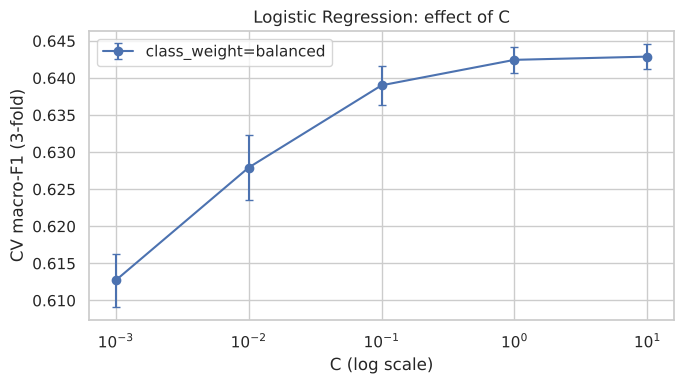

In [22]:
plt.figure(figsize=(7, 4))
for cw, g in lr_cv.groupby(lr_cv['param_logisticregression__class_weight'].astype(str)):
    plt.errorbar(g['param_logisticregression__C'].astype(float), g['mean_test_score'], yerr=g['std_test_score'],
                 marker='o', capsize=3, label=f'class_weight={cw}')
plt.xscale('log')
plt.xlabel('C (log scale)')
plt.ylabel('CV macro-F1 (3-fold)')
plt.title('Logistic Regression: effect of C')
plt.legend()
savefig('Q2.1_logreg_C_validation_curve')

In [23]:
# Impact of preprocessing on the linear model: same model, three preprocessing variants (tuning sample, 3-fold CV)
def lr_variant(pre):
    return make_pipeline(pre, LogisticRegression(max_iter=2000, **{k.split('__')[1]: v for k, v in lr_search.best_params_.items()}))

no_scale = ColumnTransformer([
    ('target_enc', TargetEncoder(random_state=SEED), HIGH_CARD),
    ('freq_enc', FrequencyEncoder(), FREQ_COLS),
    ('onehot', OneHotEncoder(handle_unknown='ignore'), LOW_CARD),
    ('num', SimpleImputer(strategy='median'), NUM_COLS)])
no_log = ColumnTransformer([
    ('target_enc', make_pipeline(TargetEncoder(random_state=SEED), StandardScaler()), HIGH_CARD),
    ('freq_enc', make_pipeline(FrequencyEncoder(), StandardScaler()), FREQ_COLS),
    ('onehot', OneHotEncoder(handle_unknown='ignore'), LOW_CARD),
    ('num', make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler()), NUM_COLS)])
prep_effect = {}
for label, pre in [('no scaling', no_scale), ('scaling, no log', no_log), ('log + scaling (used)', make_linear_preprocessor())]:
    s = cross_val_score(lr_variant(pre), X_tune, y_tune, scoring=SCORING, cv=CV3, n_jobs=N_JOBS)
    prep_effect[label] = s.mean()
prep_effect = pd.Series(prep_effect, name='CV macro-F1')
print(prep_effect.round(4))
prep_effect.to_csv(os.path.join(RES_DIR, 'Q2_logreg_preprocessing_effect.csv'))

no scaling              0.4173
scaling, no log         0.6407
log + scaling (used)    0.6429
Name: CV macro-F1, dtype: float64


In [24]:
best_lr = clone(lr_pipe).set_params(**lr_search.best_params_)
best_lr = evaluate('Logistic Regression', best_lr, 'tuned', family='linear')
coef = pd.DataFrame(best_lr[-1].coef_.T, index=best_lr[0].get_feature_names_out(),
                    columns=[f'tier {k}' for k in best_lr[-1].classes_])
print('Largest positive coefficients for tier 4 (most expensive):')
print(coef['tier 4'].sort_values(ascending=False).head(8).round(3))
print('\nLargest positive coefficients for tier 1 (cheapest):')
print(coef['tier 1'].sort_values(ascending=False).head(8).round(3))

Logistic Regression          tuned     macro-F1=0.6639  acc=0.6643  fit=32s
Largest positive coefficients for tier 4 (most expensive):
onehot__metro_MTR-08    2.473
onehot__metro_MTR-14    1.055
log_num__zones          0.769
onehot__metro_MTR-09    0.729
target_enc__zone_4      0.674
onehot__metro_MTR-11    0.435
num__max_seats          0.413
onehot__metro_MTR-01    0.406
Name: tier 4, dtype: float64

Largest positive coefficients for tier 1 (cheapest):
onehot__metro_MTR-06               1.356
onehot__metro_MTR-12               1.014
onehot__metro_MTR-13               0.946
onehot__metro_MTR-07               0.896
onehot__metro_MTR-10               0.787
target_enc__zone_1                 0.587
onehot__access_type_shared_zone    0.573
num__geo_lon                       0.511
Name: tier 1, dtype: float64


## 5. Non-tree, non-linear model: K-Nearest Neighbours (Q3)

KNN stores the training set and predicts the majority tier among the `k` closest training points
(Euclidean distance on the scaled feature space). It makes no assumption about the shape of the
decision boundary, only that *similar spaces cost alike*. Scaling is essential: without it, features
with large ranges (e.g. `open_slots_d` up to 365) would dominate the distance.

Hyperparameters: `n_neighbors` (bias–variance: small k is noisy, large k is over-smoothed) and
`weights` (uniform vs inverse-distance). Euclidean distance with brute-force search is used: tree-based
neighbour indexes do not help in ~230 dimensions, and Manhattan distance has no fast BLAS path.

In [25]:
knn_pipe = make_pipeline(make_linear_preprocessor(), KNeighborsClassifier(algorithm='brute', n_jobs=1))
knn_grid = {'kneighborsclassifier__n_neighbors': [5, 11, 21, 41, 81],
            'kneighborsclassifier__weights': ['uniform', 'distance']}
X_knn_tune, y_knn_tune = X_tune.iloc[:15000], y_tune.iloc[:15000]
t = time.time()
knn_search = GridSearchCV(knn_pipe, knn_grid, scoring=SCORING, cv=CV3, n_jobs=N_JOBS, refit=False)
knn_search.fit(X_knn_tune, y_knn_tune)
print(f'grid search: {time.time() - t:.0f}s | best {knn_search.best_params_} CV={knn_search.best_score_:.4f}')
knn_cv = pd.DataFrame(knn_search.cv_results_)

grid search: 7s | best {'kneighborsclassifier__n_neighbors': 21, 'kneighborsclassifier__weights': 'distance'} CV=0.5409


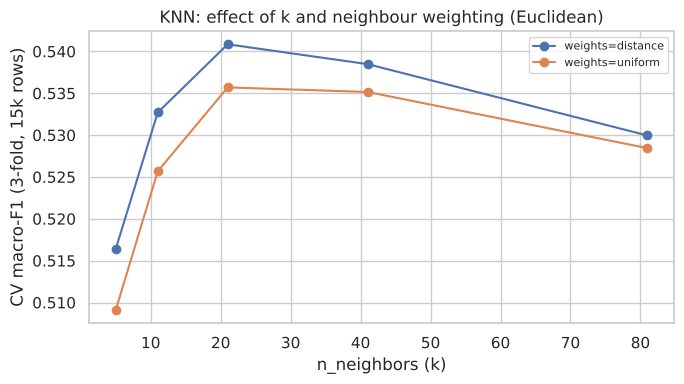

In [26]:
plt.figure(figsize=(7, 4))
for w, g in knn_cv.groupby('param_kneighborsclassifier__weights'):
    plt.plot(g['param_kneighborsclassifier__n_neighbors'].astype(int), g['mean_test_score'], marker='o',
             label=f'weights={w}')
plt.xlabel('n_neighbors (k)')
plt.ylabel('CV macro-F1 (3-fold, 15k rows)')
plt.title('KNN: effect of k and neighbour weighting (Euclidean)')
plt.legend(fontsize=8)
savefig('Q3.1_knn_k_validation_curve')

In [27]:
# Effect of training-set size on KNN (more neighbours to choose from vs prediction cost)
size_rows = []
for n in [10000, 25000, 50000]:
    idx = X_tr.sample(n, random_state=SEED).index
    m = clone(knn_pipe).set_params(**knn_search.best_params_, kneighborsclassifier__n_jobs=N_JOBS).fit(X_tr.loc[idx], y_tr.loc[idx])
    t = time.time()
    pred = m.predict(X_val)
    size_rows.append({'train_rows': n, 'holdout_macro_f1': f1_score(y_val, pred, average='macro'),
                      'predict_seconds': round(time.time() - t, 1)})
knn_size = pd.DataFrame(size_rows)
print(knn_size.round(4).to_string(index=False))
knn_size.to_csv(os.path.join(RES_DIR, 'Q3_knn_training_size.csv'), index=False)

 train_rows  holdout_macro_f1  predict_seconds
      10000            0.5369              1.9
      25000            0.5723              4.2
      50000            0.5924              8.2


In [28]:
best_knn = clone(knn_pipe).set_params(**knn_search.best_params_, kneighborsclassifier__n_jobs=N_JOBS)
best_knn = evaluate('KNN (50k sample)', best_knn, 'tuned', X_tr.loc[knn_idx], y_tr.loc[knn_idx], family='non-tree')

KNN (50k sample)             tuned     macro-F1=0.5924  acc=0.6007  fit=1s


## 6. Decision Tree (Q4)

A CART tree recursively picks the feature and threshold that most reduce impurity (Gini or entropy)
and stops when a stopping rule triggers. It needs no scaling and handles interactions naturally,
but a fully grown tree memorises the training data (high variance).

Hyperparameters: `max_depth`, `min_samples_leaf`, `criterion`, and `ccp_alpha` (cost-complexity pruning).

In [29]:
dt_pipe = make_pipeline(make_tree_preprocessor(), DecisionTreeClassifier(random_state=SEED))
dt_grid = {'decisiontreeclassifier__max_depth': [6, 10, 14, 18, 24, None],
           'decisiontreeclassifier__min_samples_leaf': [1, 10, 50, 200],
           'decisiontreeclassifier__criterion': ['gini', 'entropy']}
t = time.time()
dt_search = GridSearchCV(dt_pipe, dt_grid, scoring=SCORING, cv=CV3, n_jobs=N_JOBS, refit=False,
                         return_train_score=True)
dt_search.fit(X_tune, y_tune)
dt_grid_time = time.time() - t
print(f'grid search ({len(pd.DataFrame(dt_search.cv_results_))} configs): {dt_grid_time:.0f}s | '
      f'best {dt_search.best_params_} CV={dt_search.best_score_:.4f}')
dt_cv = pd.DataFrame(dt_search.cv_results_)

grid search (48 configs): 33s | best {'decisiontreeclassifier__criterion': 'gini', 'decisiontreeclassifier__max_depth': 10, 'decisiontreeclassifier__min_samples_leaf': 10} CV=0.5921


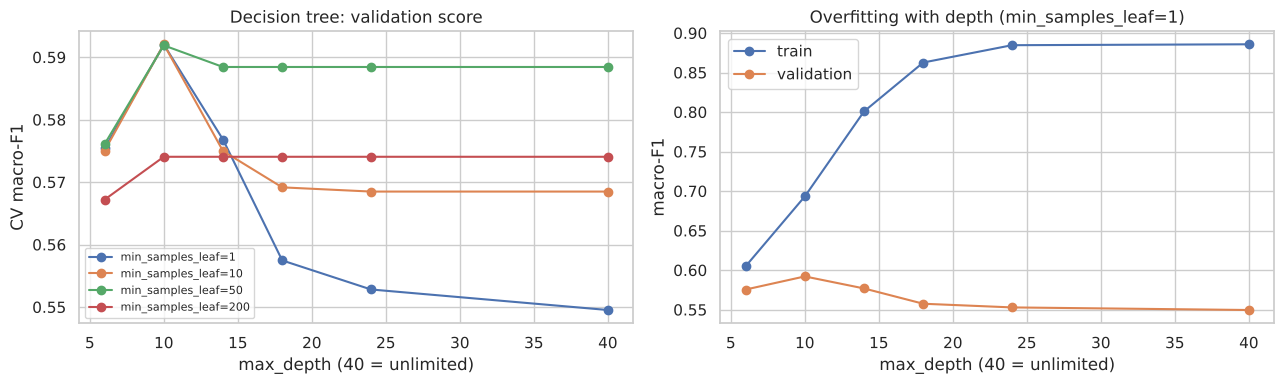

In [30]:
g = dt_cv[dt_cv['param_decisiontreeclassifier__criterion'] == dt_search.best_params_['decisiontreeclassifier__criterion']].copy()
g['depth'] = g['param_decisiontreeclassifier__max_depth'].fillna(40).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for leaf, gg in g.groupby('param_decisiontreeclassifier__min_samples_leaf'):
    axes[0].plot(gg['depth'], gg['mean_test_score'], marker='o', label=f'min_samples_leaf={leaf}')
axes[0].set(xlabel='max_depth (40 = unlimited)', ylabel='CV macro-F1', title='Decision tree: validation score')
axes[0].legend(fontsize=8)
gg = g[g['param_decisiontreeclassifier__min_samples_leaf'] == 1]
axes[1].plot(gg['depth'], gg['mean_train_score'], marker='o', label='train')
axes[1].plot(gg['depth'], gg['mean_test_score'], marker='o', label='validation')
axes[1].set(xlabel='max_depth (40 = unlimited)', ylabel='macro-F1', title='Overfitting with depth (min_samples_leaf=1)')
axes[1].legend()
savefig('Q4.1_decision_tree_depth_leaf')

Decision Tree                tuned     macro-F1=0.6441  acc=0.6466  fit=11s


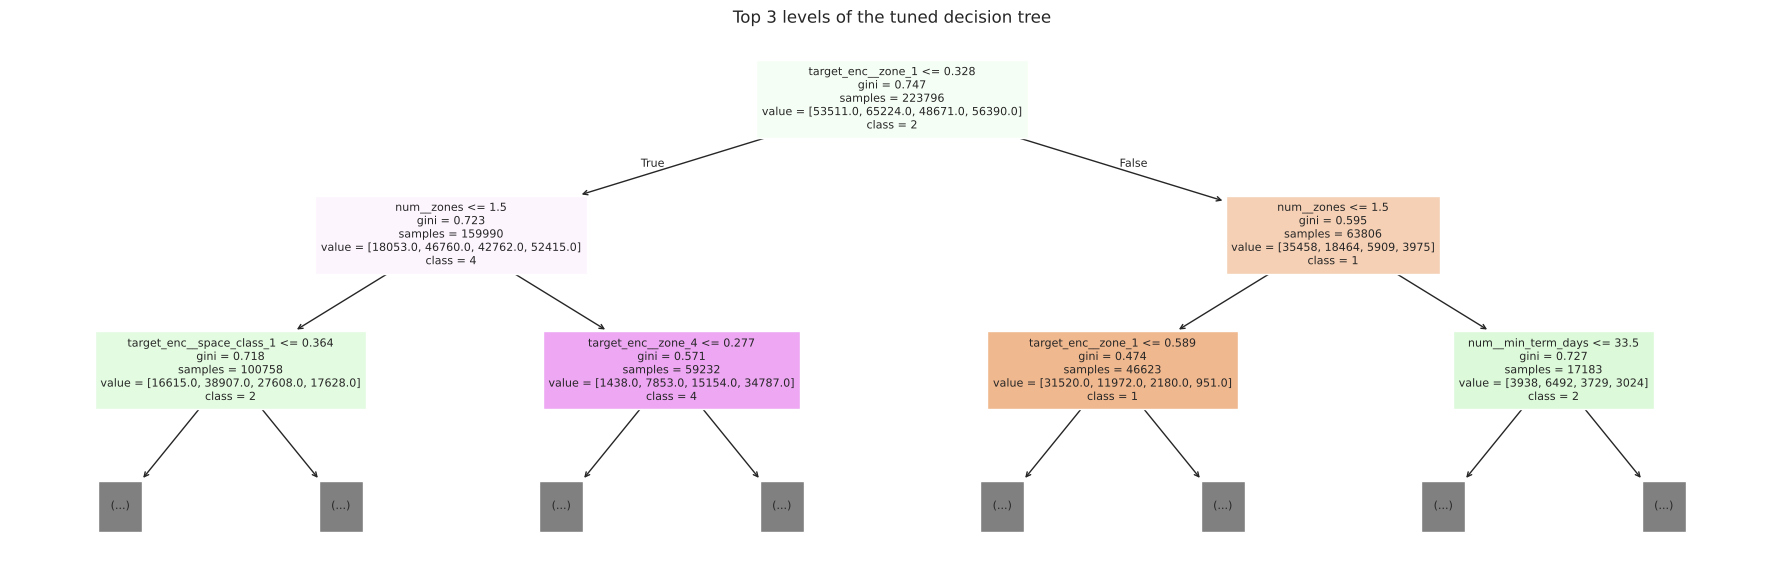

In [31]:
best_dt = clone(dt_pipe).set_params(**dt_search.best_params_)
best_dt = evaluate('Decision Tree', best_dt, 'tuned', family='tree')
plt.figure(figsize=(18, 6))
plot_tree(best_dt[-1], max_depth=2, feature_names=list(best_dt[0].get_feature_names_out()),
          class_names=[str(c) for c in best_dt[-1].classes_], filled=True, fontsize=8, impurity=True)
plt.title('Top 3 levels of the tuned decision tree')
savefig('Q4.2_decision_tree_top_levels')

## 7. Bagging: Random Forest (Q5)

A random forest trains many deep trees, each on a **bootstrap sample** of rows and considering a
**random subset of features** (`max_features`) at every split, then averages their class
probabilities. Bootstrapping plus feature subsampling de-correlates the trees, so averaging cuts
variance while keeping the low bias of deep trees.

Hyperparameters: `n_estimators`, `max_features`, `max_depth`, `min_samples_leaf`, `class_weight`.
Randomised search is used because the space is large and each fit is relatively costly.

In [32]:
rf_pipe = make_pipeline(make_tree_preprocessor(), RandomForestClassifier(n_jobs=1, random_state=SEED))
rf_space = {'randomforestclassifier__n_estimators': [100, 200],
            'randomforestclassifier__max_features': ['sqrt', 0.2, 0.35],
            'randomforestclassifier__max_depth': [None, 20, 30],
            'randomforestclassifier__min_samples_leaf': [1, 2, 5],
            'randomforestclassifier__class_weight': [None, 'balanced_subsample']}
t = time.time()
rf_search = RandomizedSearchCV(rf_pipe, rf_space, n_iter=6, scoring=SCORING, cv=CV3, n_jobs=N_JOBS,
                               random_state=SEED, refit=False)
rf_search.fit(X_tune, y_tune)
print(f'random search: {time.time() - t:.0f}s | best {rf_search.best_params_} CV={rf_search.best_score_:.4f}')
rf_cv = pd.DataFrame(rf_search.cv_results_).sort_values('rank_test_score')
rf_cv[[c for c in rf_cv.columns if c.startswith('param_')] + ['mean_test_score', 'std_test_score']].head(12)

random search: 73s | best {'randomforestclassifier__n_estimators': 200, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__max_features': 0.35, 'randomforestclassifier__max_depth': None, 'randomforestclassifier__class_weight': 'balanced_subsample'} CV=0.6591


,param_randomforestclassifier__n_estimators,param_randomforestclassifier__min_samples_leaf,param_randomforestclassifier__max_features,param_randomforestclassifier__max_depth,param_randomforestclassifier__class_weight,mean_test_score,std_test_score
5,200,1,0.35,None,balanced_subsample,0.659071,0.003752
3,200,5,0.2,20,balanced_subsample,0.658063,0.005030
4,100,2,0.2,None,balanced_subsample,0.654723,0.006979
1,100,5,0.2,None,NaN,0.654572,0.006408
0,200,5,sqrt,20,balanced_subsample,0.653124,0.004912
2,100,5,sqrt,None,NaN,0.646908,0.008530


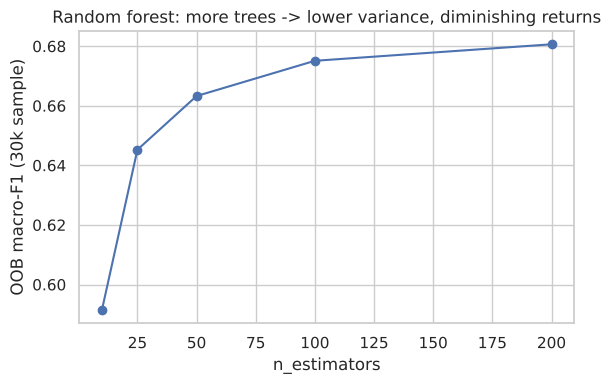

 n_estimators  oob_macro_f1
           10        0.5914
           25        0.6453
           50        0.6633
          100        0.6751
          200        0.6806


In [33]:
# Effect of the number of trees (OOB score uses the out-of-bag rows as a free validation set)
best_rf_params = {k.split('__')[1]: v for k, v in rf_search.best_params_.items()}
pre = make_tree_preprocessor().fit(X_tune, y_tune)
Xt = pre.transform(X_tune)
rf_curve = []
for n in [10, 25, 50, 100, 200]:
    p_ = dict(best_rf_params, n_estimators=n)
    rf_ = RandomForestClassifier(**p_, oob_score=True, n_jobs=N_JOBS, random_state=SEED).fit(Xt, y_tune)
    oob_pred = rf_.classes_[rf_.oob_decision_function_.argmax(1)]
    rf_curve.append({'n_estimators': n, 'oob_macro_f1': f1_score(y_tune, oob_pred, average='macro')})
rf_curve = pd.DataFrame(rf_curve)
plt.figure(figsize=(6, 4))
plt.plot(rf_curve['n_estimators'], rf_curve['oob_macro_f1'], marker='o')
plt.xlabel('n_estimators')
plt.ylabel('OOB macro-F1 (30k sample)')
plt.title('Random forest: more trees -> lower variance, diminishing returns')
savefig('Q5.1_random_forest_n_estimators_oob')
print(rf_curve.round(4).to_string(index=False))

Random Forest                tuned     macro-F1=0.7247  acc=0.7286  fit=137s


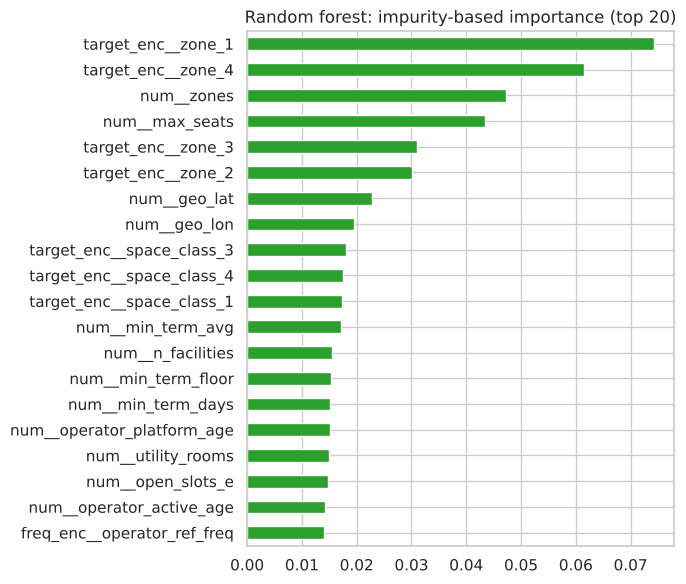

In [34]:
best_rf = clone(rf_pipe).set_params(**rf_search.best_params_, randomforestclassifier__n_jobs=N_JOBS)
best_rf = evaluate('Random Forest', best_rf, 'tuned', family='bagging')
rf_imp = pd.Series(best_rf[-1].feature_importances_, index=best_rf[0].get_feature_names_out()).sort_values()
plt.figure(figsize=(7, 6))
rf_imp.tail(20).plot.barh(color='tab:green')
plt.title('Random forest: impurity-based importance (top 20)')
savefig('Q5.2_random_forest_feature_importance')

## 8. Boosting: LightGBM (Q6)

Gradient boosting builds trees **sequentially**. Each new tree fits the gradient of the multi-class
log-loss with respect to the current predictions (i.e. what the ensemble still gets wrong), and its
output is added with a shrinkage factor `learning_rate`. LightGBM grows trees leaf-wise, bins
features into histograms (fast on 280k rows), and handles missing values natively.

Hyperparameters: `learning_rate` × `n_estimators` (step size vs number of steps), `num_leaves` /
`max_depth` (tree complexity), `min_child_samples`, `subsample` / `colsample_bytree` (stochasticity),
`reg_lambda` (L2 on leaf weights).

In [35]:
lgb_pipe = make_pipeline(make_tree_preprocessor(impute=False),
                         lgb.LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1, subsample_freq=1))
lgb_space = {'lgbmclassifier__n_estimators': [200, 400],
             'lgbmclassifier__learning_rate': [0.03, 0.06, 0.1],
             'lgbmclassifier__num_leaves': [31, 63, 127, 255],
             'lgbmclassifier__min_child_samples': [10, 30, 80],
             'lgbmclassifier__subsample': [0.7, 0.85, 1.0],
             'lgbmclassifier__colsample_bytree': [0.3, 0.5, 0.8],
             'lgbmclassifier__reg_lambda': [0, 1, 5]}
t = time.time()
lgb_search = RandomizedSearchCV(lgb_pipe, lgb_space, n_iter=8, scoring=SCORING, cv=CV3, n_jobs=N_JOBS,
                                random_state=SEED, refit=False)
lgb_search.fit(X_tune, y_tune)
print(f'random search: {time.time() - t:.0f}s | best {lgb_search.best_params_} CV={lgb_search.best_score_:.4f}')
lgb_cv = pd.DataFrame(lgb_search.cv_results_).sort_values('rank_test_score')
lgb_cv[[c for c in lgb_cv.columns if c.startswith('param_')] + ['mean_test_score', 'std_test_score', 'mean_fit_time']].head(16)

random search: 155s | best {'lgbmclassifier__subsample': 0.85, 'lgbmclassifier__reg_lambda': 0, 'lgbmclassifier__num_leaves': 63, 'lgbmclassifier__n_estimators': 400, 'lgbmclassifier__min_child_samples': 10, 'lgbmclassifier__learning_rate': 0.1, 'lgbmclassifier__colsample_bytree': 0.5} CV=0.6751


,param_lgbmclassifier__subsample,param_lgbmclassifier__reg_lambda,param_lgbmclassifier__num_leaves,param_lgbmclassifier__n_estimators,param_lgbmclassifier__min_child_samples,param_lgbmclassifier__learning_rate,param_lgbmclassifier__colsample_bytree,mean_test_score,std_test_score,mean_fit_time
0,0.85,0,63,400,10,0.10,0.5,0.675066,0.008660,21.116751
4,1.00,1,63,400,10,0.10,0.5,0.674940,0.008902,21.955394
3,0.85,5,255,400,80,0.10,0.5,0.673197,0.005391,25.548337
6,1.00,1,255,400,80,0.06,0.8,0.671821,0.007119,24.819164
5,0.70,5,63,200,10,0.10,0.5,0.671684,0.006977,11.414404
7,0.70,0,31,400,80,0.06,0.5,0.671481,0.006055,16.931393
2,1.00,1,255,400,80,0.03,0.5,0.670951,0.006207,29.569079
1,0.85,0,127,200,80,0.03,0.8,0.667697,0.006866,10.902995


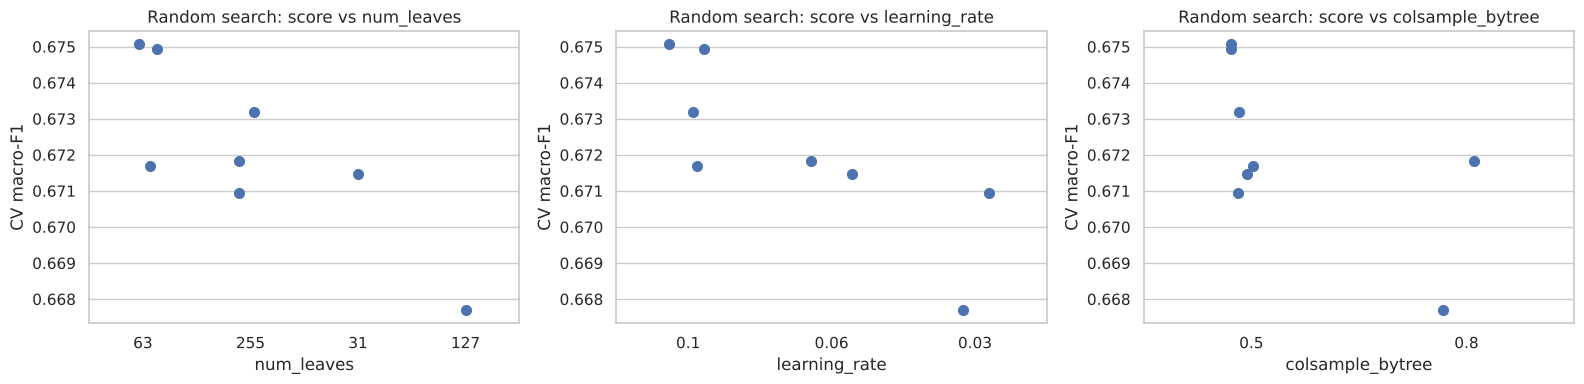

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, p_ in zip(axes, ['num_leaves', 'learning_rate', 'colsample_bytree']):
    col = f'param_lgbmclassifier__{p_}'
    sns.stripplot(x=lgb_cv[col].astype(str), y=lgb_cv['mean_test_score'], ax=ax, size=8, jitter=0.15)
    ax.set(xlabel=p_, ylabel='CV macro-F1', title=f'Random search: score vs {p_}')
savefig('Q9.1_lightgbm_random_search')

learning_rate=0.1: best_iteration=978, early-stop-set macro-F1=0.7371


learning_rate=0.05: best_iteration=2078, early-stop-set macro-F1=0.7428


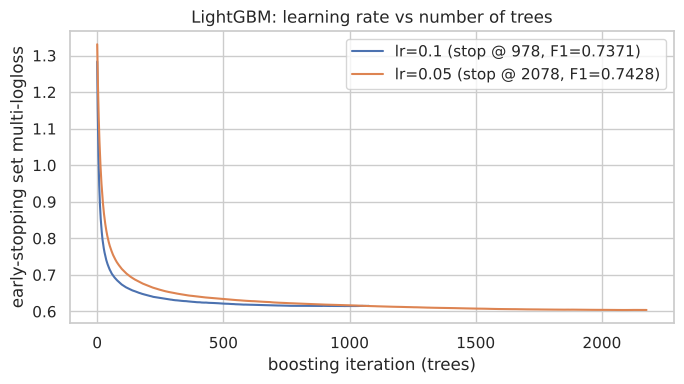

In [37]:
# Learning-rate / n_estimators trade-off with early stopping on the hold-out
best_lgb_params = {k.split('__')[1]: v for k, v in lgb_search.best_params_.items()}
# The early-stopping set is carved out of the TRAINING part, so the hold-out stays untouched.
X_in, X_es, y_in, y_es = train_test_split(X_tr, y_tr, test_size=0.1, stratify=y_tr, random_state=SEED)
pre_lgb = make_tree_preprocessor(impute=False).fit(X_in, y_in)
Xin_t, Xes_t = pre_lgb.transform(X_in), pre_lgb.transform(X_es)
curves = {}
for lr_ in [0.1, 0.05]:
    p_ = dict(best_lgb_params, learning_rate=lr_, n_estimators=3000)
    m = lgb.LGBMClassifier(**p_, random_state=SEED, n_jobs=N_JOBS, verbose=-1, subsample_freq=1)
    m.fit(Xin_t, y_in, eval_set=[(Xes_t, y_es)], eval_metric='multi_logloss',
          callbacks=[lgb.early_stopping(100, verbose=False)])
    curves[lr_] = (m.evals_result_['valid_0']['multi_logloss'], m.best_iteration_,
                   f1_score(y_es, m.predict(Xes_t), average='macro'))
    print(f'learning_rate={lr_}: best_iteration={m.best_iteration_}, early-stop-set macro-F1={curves[lr_][2]:.4f}')
plt.figure(figsize=(7, 4))
for lr_, (curve, it, f1) in curves.items():
    plt.plot(curve, label=f'lr={lr_} (stop @ {it}, F1={f1:.4f})')
plt.xlabel('boosting iteration (trees)')
plt.ylabel('early-stopping set multi-logloss')
plt.title('LightGBM: learning rate vs number of trees')
plt.legend()
savefig('Q6.1_lightgbm_learning_curve')
BEST_LR_LGB = max(curves, key=lambda k: curves[k][2])
BEST_ITER_LGB = curves[BEST_LR_LGB][1]

In [38]:
best_lgb = clone(lgb_pipe).set_params(**lgb_search.best_params_, lgbmclassifier__n_jobs=N_JOBS)
best_lgb = evaluate('LightGBM', best_lgb, 'tuned', family='boosting')
lgb_es = clone(lgb_pipe).set_params(**{**lgb_search.best_params_, 'lgbmclassifier__n_jobs': N_JOBS,
                                       'lgbmclassifier__learning_rate': BEST_LR_LGB,
                                       'lgbmclassifier__n_estimators': BEST_ITER_LGB})
lgb_es = evaluate('LightGBM (lr+early stop)', lgb_es, 'tuned', family='boosting')

LightGBM                     tuned     macro-F1=0.7311  acc=0.7348  fit=57s


LightGBM (lr+early stop)     tuned     macro-F1=0.7442  acc=0.7475  fit=274s


In [39]:
# XGBoost: a second boosting implementation, tuned with a small randomised search
xgb_pipe = make_pipeline(make_tree_preprocessor(impute=False),
                         EncodeLabels(xgb.XGBClassifier(tree_method='hist', random_state=SEED, n_jobs=1)))
xgb_space = {'encodelabels__estimator__n_estimators': [300, 600],
             'encodelabels__estimator__learning_rate': [0.05, 0.1],
             'encodelabels__estimator__max_depth': [6, 8, 10],
             'encodelabels__estimator__min_child_weight': [1, 5],
             'encodelabels__estimator__subsample': [0.8, 1.0],
             'encodelabels__estimator__colsample_bytree': [0.4, 0.7]}
t = time.time()
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_space, n_iter=4, scoring=SCORING, cv=CV3, n_jobs=N_JOBS,
                                random_state=SEED, refit=False)
xgb_search.fit(X_tune, y_tune)
print(f'random search: {time.time() - t:.0f}s | best {xgb_search.best_params_} CV={xgb_search.best_score_:.4f}')
best_xgb = clone(xgb_pipe).set_params(**xgb_search.best_params_, encodelabels__estimator__n_jobs=N_JOBS)
best_xgb = evaluate('XGBoost', best_xgb, 'tuned', family='boosting')

random search: 96s | best {'encodelabels__estimator__subsample': 0.8, 'encodelabels__estimator__n_estimators': 600, 'encodelabels__estimator__min_child_weight': 5, 'encodelabels__estimator__max_depth': 10, 'encodelabels__estimator__learning_rate': 0.1, 'encodelabels__estimator__colsample_bytree': 0.7} CV=0.6753


XGBoost                      tuned     macro-F1=0.7423  acc=0.7455  fit=146s


## 9. Voting and Stacking (Q7)

* **Soft voting** averages the predicted class probabilities of the base models (optionally
  weighted) and picks the most probable tier. **Hard voting** takes the majority label.
* **Stacking** trains a *meta-learner* (here logistic regression) on **out-of-fold** probabilities of
  the base models, so it learns how much to trust each model for each tier.

Base models come from different families (linear, bagging, boosting) so their errors are less
correlated. Each base model keeps its own preprocessing pipeline.

In [40]:
vote_bases = [('lr', clone(best_lr)), ('rf', clone(best_rf)), ('lgb', clone(lgb_es)), ('xgb', clone(best_xgb))]
vote = VotingClassifier(vote_bases, voting='soft', n_jobs=1)
vote = evaluate('Soft Voting (equal weights)', vote, 'ensemble', family='ensemble')
# `voting` and `weights` are only used at predict time, so other variants reuse the fitted base models
VOTE_VARIANTS = {'Soft Voting (equal weights)': dict(voting='soft', weights=None)}
for label, params in [('Soft Voting (boosting x2)', dict(voting='soft', weights=[1, 1, 2, 2])),
                      ('Soft Voting (no LR)', dict(voting='soft', weights=[0, 1, 1, 1])),
                      ('Hard Voting', dict(voting='hard', weights=None))]:
    vote.set_params(**params)
    pred = vote.predict(X_val)
    RESULTS.append(dict(model=label, family='ensemble', stage='ensemble', train_rows=len(X_tr),
                        holdout_macro_f1=f1_score(y_val, pred, average='macro'),
                        holdout_accuracy=(pred == y_val.to_numpy()).mean(), fit_seconds=0.0))
    VOTE_VARIANTS[label] = params
    print(f"{label:<28} ensemble  macro-F1={RESULTS[-1]['holdout_macro_f1']:.4f}  (re-uses fitted base models)")
_ = vote.set_params(voting="soft", weights=None)  # restore default settings

Soft Voting (equal weights)  ensemble  macro-F1=0.7426  acc=0.7455  fit=591s


Soft Voting (boosting x2)    ensemble  macro-F1=0.7443  (re-uses fitted base models)


Soft Voting (no LR)          ensemble  macro-F1=0.7445  (re-uses fitted base models)


Hard Voting                  ensemble  macro-F1=0.7393  (re-uses fitted base models)


In [41]:
stack = StackingClassifier(
    estimators=[('lr', clone(best_lr)), ('rf', clone(best_rf)), ('lgb', clone(lgb_es))],
    final_estimator=LogisticRegression(max_iter=2000, C=1.0),
    cv=StratifiedKFold(2, shuffle=True, random_state=SEED), stack_method='predict_proba', n_jobs=1)
stack = evaluate('Stacking (LR meta)', stack, 'ensemble', family='ensemble')
meta_coef = pd.DataFrame(stack.final_estimator_.coef_, index=[f'tier {c}' for c in stack.classes_],
                         columns=[f'{n}:p{c}' for n, _ in stack.estimators for c in LABELS])
print('Meta-learner weight of each base model (sum of |coef| over its 4 probability columns):')
print(meta_coef.abs().T.groupby(lambda s: s.split(':')[0]).sum().sum(axis=1).sort_values(ascending=False).round(2))

Stacking (LR meta)           ensemble  macro-F1=0.7456  acc=0.7479  fit=1022s
Meta-learner weight of each base model (sum of |coef| over its 4 probability columns):
lgb    29.30
rf      7.13
lr      3.16
dtype: float64


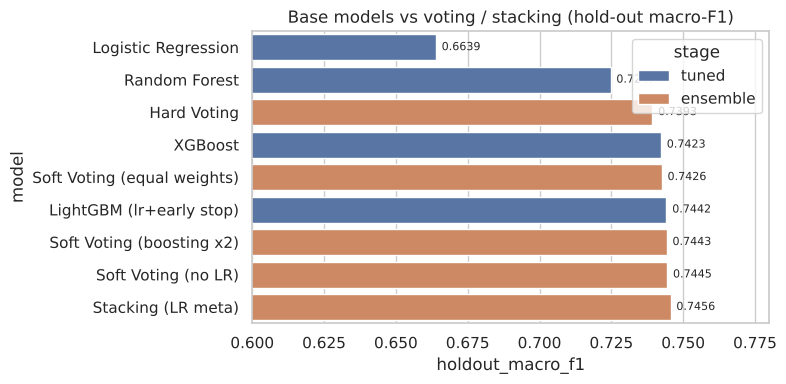

In [42]:
res = pd.DataFrame(RESULTS)
ens = pd.concat([res[(res.stage == 'tuned') & res.model.isin(['Logistic Regression', 'Random Forest',
                                                             'LightGBM (lr+early stop)', 'XGBoost'])],
                 res[res.stage == 'ensemble']]).sort_values('holdout_macro_f1')
plt.figure(figsize=(8, 4))
ax = sns.barplot(data=ens, y='model', x='holdout_macro_f1', hue='stage', dodge=False)
for i, v in enumerate(ens['holdout_macro_f1']):
    ax.text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=8)
plt.xlim(0.6, 0.78)
plt.title('Base models vs voting / stacking (hold-out macro-F1)')
savefig('Q7.1_voting_stacking_comparison')

## 10. Hyperparameter-tuning strategy (Q8)

**Cross-validation strategies compared.** Using the tuned logistic regression on the 30k sample:
a single hold-out split vs stratified k-fold with k = 3, 5 and 10. The question is how stable the
estimate is and what it costs.

In [43]:
cv_rows = []
cv_model = clone(best_lr)
for label, cv in [('Hold-out 80/20 (5 random seeds)', None), ('KFold k=5 (not stratified)', KFold(5, shuffle=True, random_state=SEED)),
                  ('StratifiedKFold k=3', StratifiedKFold(3, shuffle=True, random_state=SEED)),
                  ('StratifiedKFold k=5', StratifiedKFold(5, shuffle=True, random_state=SEED)),
                  ('StratifiedKFold k=10', StratifiedKFold(10, shuffle=True, random_state=SEED))]:
    t = time.time()
    if cv is None:
        scores = []
        for s in range(5):
            a, b, ya, yb = train_test_split(X_tune, y_tune, test_size=0.2, stratify=y_tune, random_state=s)
            scores.append(f1_score(yb, clone(cv_model).fit(a, ya).predict(b), average='macro'))
        scores = np.array(scores)
    else:
        scores = cross_val_score(cv_model, X_tune, y_tune, scoring=SCORING, cv=cv, n_jobs=N_JOBS)
    cv_rows.append({'strategy': label, 'mean_macro_f1': scores.mean(), 'std': scores.std(),
                    'n_fits': len(scores), 'seconds': round(time.time() - t, 1)})
cv_strat = pd.DataFrame(cv_rows)
cv_strat.to_csv(os.path.join(RES_DIR, 'Q8_cv_strategy_comparison.csv'), index=False)
print(cv_strat.round(4).to_string(index=False))

                       strategy  mean_macro_f1    std  n_fits  seconds
Hold-out 80/20 (5 random seeds)         0.6451 0.0039       5     48.1
     KFold k=5 (not stratified)         0.6444 0.0043       5      8.4
            StratifiedKFold k=3         0.6429 0.0017       3      3.7
            StratifiedKFold k=5         0.6436 0.0035       5      8.2
           StratifiedKFold k=10         0.6454 0.0054      10     14.0


**Search strategies compared.** The same decision-tree search space is explored with exhaustive grid
search (already run above), random search (12 of the 48 configurations) and successive halving
(many configurations on few rows, only the best promoted to more data).

                          method  configs_tried  best_cv_macro_f1  seconds                                                                                                                            best_params
                    GridSearchCV             48            0.5921     33.3 {'decisiontreeclassifier__criterion': 'gini', 'decisiontreeclassifier__max_depth': 10, 'decisiontreeclassifier__min_samples_leaf': 10}
  RandomizedSearchCV (n_iter=12)             12            0.5920      8.4  {'decisiontreeclassifier__min_samples_leaf': 1, 'decisiontreeclassifier__max_depth': 10, 'decisiontreeclassifier__criterion': 'gini'}
HalvingRandomSearchCV (factor=3)             48            0.5711      8.6 {'decisiontreeclassifier__min_samples_leaf': 50, 'decisiontreeclassifier__max_depth': 10, 'decisiontreeclassifier__criterion': 'gini'}


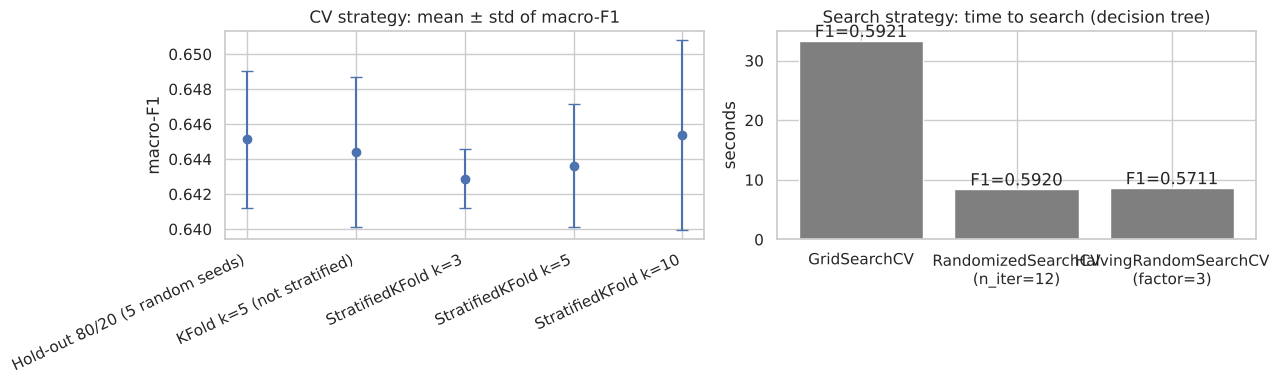

In [44]:
search_rows = [{'method': 'GridSearchCV', 'configs_tried': len(dt_cv), 'best_cv_macro_f1': dt_search.best_score_,
                'seconds': round(dt_grid_time, 1), 'best_params': str(dt_search.best_params_)}]
t = time.time()
rs = RandomizedSearchCV(dt_pipe, dt_grid, n_iter=12, scoring=SCORING, cv=CV3, n_jobs=N_JOBS,
                        random_state=SEED, refit=False).fit(X_tune, y_tune)
search_rows.append({'method': 'RandomizedSearchCV (n_iter=12)', 'configs_tried': 12,
                    'best_cv_macro_f1': rs.best_score_, 'seconds': round(time.time() - t, 1),
                    'best_params': str(rs.best_params_)})
t = time.time()
hs = HalvingRandomSearchCV(dt_pipe, dt_grid, n_candidates=48, factor=3, scoring=SCORING, cv=CV3,
                           n_jobs=N_JOBS, random_state=SEED, refit=False, min_resources=2000).fit(X_tune, y_tune)
search_rows.append({'method': 'HalvingRandomSearchCV (factor=3)', 'configs_tried': int(hs.n_candidates_[0]),
                    'best_cv_macro_f1': hs.best_score_, 'seconds': round(time.time() - t, 1),
                    'best_params': str(hs.best_params_)})
search_cmp = pd.DataFrame(search_rows)
search_cmp.to_csv(os.path.join(RES_DIR, 'Q8_search_strategy_comparison.csv'), index=False)
print(search_cmp.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].errorbar(cv_strat['strategy'], cv_strat['mean_macro_f1'], yerr=cv_strat['std'], fmt='o', capsize=4)
axes[0].set(title='CV strategy: mean ± std of macro-F1', ylabel='macro-F1')
axes[0].tick_params(axis='x', rotation=25)
for lbl in axes[0].get_xticklabels():
    lbl.set_ha('right')
axes[1].bar(search_cmp['method'].str.replace(' ', '\n', n=1), search_cmp['seconds'], color='tab:gray')
for i, (s, f) in enumerate(zip(search_cmp['seconds'], search_cmp['best_cv_macro_f1'])):
    axes[1].text(i, s, f'F1={f:.4f}', ha='center', va='bottom')
axes[1].set(title='Search strategy: time to search (decision tree)', ylabel='seconds')
savefig('Q8.1_cv_and_search_strategies')

## 11. Tuning summary and before/after comparison (Q9, Q10)

In [45]:
tuning_summary = pd.DataFrame([
    {'model': 'Logistic Regression', 'search': 'GridSearchCV', 'configs': len(lr_cv), 'cv': 'StratifiedKFold(3), 30k',
     'best_cv_macro_f1': lr_search.best_score_, 'best_params': lr_search.best_params_},
    {'model': 'KNN', 'search': 'GridSearchCV', 'configs': len(knn_cv), 'cv': 'StratifiedKFold(3), 15k',
     'best_cv_macro_f1': knn_search.best_score_, 'best_params': knn_search.best_params_},
    {'model': 'Decision Tree', 'search': 'GridSearchCV', 'configs': len(dt_cv), 'cv': 'StratifiedKFold(3), 30k',
     'best_cv_macro_f1': dt_search.best_score_, 'best_params': dt_search.best_params_},
    {'model': 'Random Forest', 'search': 'RandomizedSearchCV', 'configs': len(rf_cv), 'cv': 'StratifiedKFold(3), 30k',
     'best_cv_macro_f1': rf_search.best_score_, 'best_params': rf_search.best_params_},
    {'model': 'LightGBM', 'search': 'RandomizedSearchCV + early stopping', 'configs': len(lgb_cv), 'cv': 'StratifiedKFold(3), 30k',
     'best_cv_macro_f1': lgb_search.best_score_, 'best_params': dict(lgb_search.best_params_, lr_final=BEST_LR_LGB, n_estimators_final=BEST_ITER_LGB)},
    {'model': 'XGBoost', 'search': 'RandomizedSearchCV', 'configs': len(xgb_search.cv_results_['params']), 'cv': 'StratifiedKFold(3), 30k',
     'best_cv_macro_f1': xgb_search.best_score_, 'best_params': xgb_search.best_params_},
])
tuning_summary['best_params'] = tuning_summary['best_params'].map(
    lambda d: {k.split('__')[-1]: (v.item() if hasattr(v, 'item') else v) for k, v in d.items()})
tuning_summary.to_csv(os.path.join(RES_DIR, 'Q9_tuning_summary.csv'), index=False)
with open(os.path.join(RES_DIR, 'Q9_best_params.json'), 'w') as f:
    json.dump({r.model: r.best_params for r in tuning_summary.itertuples()}, f, indent=2, default=str)
tuning_summary

,model,search,configs,cv,best_cv_macro_f1,best_params
0,Logistic Regression,GridSearchCV,10,"StratifiedKFold(3), 30k",0.642882,"{'C': 10, 'class_weight': 'balanced'}"
1,KNN,GridSearchCV,10,"StratifiedKFold(3), 15k",0.540850,"{'n_neighbors': 21, 'weights': 'distance'}"
2,Decision Tree,GridSearchCV,48,"StratifiedKFold(3), 30k",0.592063,"{'criterion': 'gini', 'max_depth': 10, 'min_sa..."
3,Random Forest,RandomizedSearchCV,6,"StratifiedKFold(3), 30k",0.659071,"{'n_estimators': 200, 'min_samples_leaf': 1, '..."
4,LightGBM,RandomizedSearchCV + early stopping,8,"StratifiedKFold(3), 30k",0.675066,"{'subsample': 0.85, 'reg_lambda': 0, 'num_leav..."
5,XGBoost,RandomizedSearchCV,4,"StratifiedKFold(3), 30k",0.675329,"{'subsample': 0.8, 'n_estimators': 600, 'min_c..."


stage                baseline   tuned    gain
model                                        
KNN (50k sample)       0.5679  0.5924  0.0245
Decision Tree          0.6135  0.6441  0.0306
Logistic Regression    0.6597  0.6639  0.0042
Random Forest          0.7191  0.7247  0.0057
XGBoost                0.7149  0.7423  0.0274
LightGBM               0.6980  0.7442  0.0462


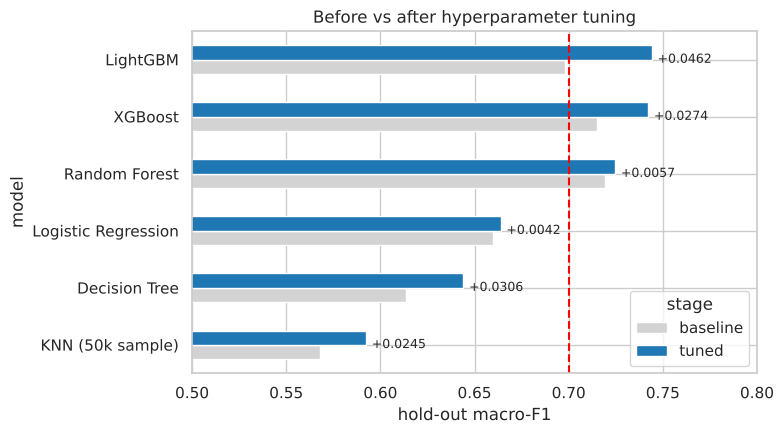

In [46]:
res = pd.DataFrame(RESULTS)
res.to_csv(os.path.join(RES_DIR, 'all_model_scores.csv'), index=False)
ba = res[res.stage.isin(['baseline', 'tuned'])].copy()
ba.loc[ba.model == 'LightGBM (lr+early stop)', 'model'] = 'LightGBM'
ba = ba.sort_values('holdout_macro_f1').drop_duplicates(['model', 'stage'], keep='last')
before_after = ba.pivot(index='model', columns='stage', values='holdout_macro_f1')[['baseline', 'tuned']]
before_after['gain'] = before_after['tuned'] - before_after['baseline']
before_after = before_after.sort_values('tuned')
before_after.to_csv(os.path.join(RES_DIR, 'Q10_before_after_tuning.csv'))
print(before_after.round(4))

ax = before_after[['baseline', 'tuned']].plot.barh(figsize=(8, 4.5), color=['lightgray', 'tab:blue'])
for i, (b, t_) in enumerate(zip(before_after['baseline'], before_after['tuned'])):
    ax.text(max(b, t_) + 0.003, i, f'{t_ - b:+.4f}', va='center', fontsize=9)
plt.axvline(0.70, ls='--', c='red')
plt.xlim(0.5, 0.8)
plt.xlabel('hold-out macro-F1')
plt.title('Before vs after hyperparameter tuning')
savefig('Q10.1_before_after_tuning')

## 12. Error analysis of the best model

In [47]:
res = pd.DataFrame(RESULTS)
cands = res[res.stage.isin(['tuned', 'ensemble'])].sort_values('holdout_macro_f1', ascending=False)
print(cands[['model', 'stage', 'holdout_macro_f1', 'holdout_accuracy', 'fit_seconds']].round(4).to_string(index=False))
model_lookup = {'Logistic Regression': best_lr, 'Decision Tree': best_dt, 'Random Forest': best_rf,
                'LightGBM': best_lgb, 'LightGBM (lr+early stop)': lgb_es, 'XGBoost': best_xgb,
                'Stacking (LR meta)': stack}
for label, params in VOTE_VARIANTS.items():
    model_lookup[label] = clone(vote).set_params(**params)
best_name = next(n for n in cands['model'] if n in model_lookup)
best_model = model_lookup[best_name]
if best_name in VOTE_VARIANTS:                 # re-use the fitted voter with the winning settings
    best_model = vote.set_params(**VOTE_VARIANTS[best_name])
print('\nBest model on hold-out:', best_name)
val_pred = best_model.predict(X_val)
print(classification_report(y_val, val_pred, digits=4))

                      model    stage  holdout_macro_f1  holdout_accuracy  fit_seconds
         Stacking (LR meta) ensemble            0.7456            0.7479       1022.2
        Soft Voting (no LR) ensemble            0.7445            0.7478          0.0
  Soft Voting (boosting x2) ensemble            0.7443            0.7474          0.0
   LightGBM (lr+early stop)    tuned            0.7442            0.7475        274.2
Soft Voting (equal weights) ensemble            0.7426            0.7455        591.3
                    XGBoost    tuned            0.7423            0.7455        146.1
                Hard Voting ensemble            0.7393            0.7425          0.0
                   LightGBM    tuned            0.7311            0.7348         57.2
              Random Forest    tuned            0.7247            0.7286        137.4
        Logistic Regression    tuned            0.6639            0.6643         32.5
              Decision Tree    tuned            0.6441

              precision    recall  f1-score   support

           1     0.8428    0.8415    0.8421     13378
           2     0.6931    0.7393    0.7155     16306
           3     0.6174    0.5946    0.6058     12168
           4     0.8378    0.8012    0.8191     14098

    accuracy                         0.7479     55950
   macro avg     0.7478    0.7441    0.7456     55950
weighted avg     0.7489    0.7479    0.7480     55950



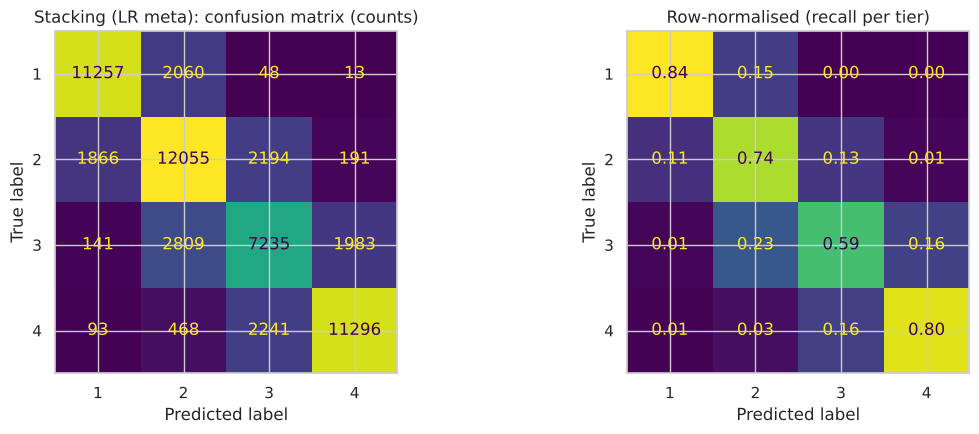

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_val, val_pred), display_labels=LABELS).plot(ax=axes[0], colorbar=False, values_format='d')
axes[0].set_title(f'{best_name}: confusion matrix (counts)')
ConfusionMatrixDisplay(confusion_matrix(y_val, val_pred, normalize='true'), display_labels=LABELS).plot(
    ax=axes[1], colorbar=False, values_format='.2f')
axes[1].set_title('Row-normalised (recall per tier)')
savefig('error_confusion_matrix')

Most errors fall between **adjacent** tiers (1↔2, 2↔3, 3↔4). Tier 4 vs tier 1 confusions are rare,
as expected for an ordinal target where neighbouring price bands overlap.

## 13. Final model and submission

The best configuration is refitted on **all** 279,746 labelled rows (training part + hold-out) and
predicts the test set. The submission keeps the required format `ID,price_tier`.

In [49]:
final_model = clone(best_model)
t = time.time()
final_model.fit(X_full, y_full)
print(f'final refit of {best_name} on all rows: {time.time() - t:.0f}s')
test_pred = final_model.predict(X_test)
submission = pd.DataFrame({'ID': test_raw[ID].values, 'price_tier': test_pred.astype(int)})
submission.to_csv(os.path.join(OUT_DIR, 'submission.csv'), index=False)
print(submission.shape)
print(submission['price_tier'].value_counts(normalize=True).sort_index().round(3))
submission.head()

final refit of Stacking (LR meta) on all rows: 1299s


(114538, 2)
price_tier
1    0.226
2    0.333
3    0.203
4    0.238
Name: proportion, dtype: float64


,ID,price_tier
0,0,1
1,1,2
2,2,1
3,3,2
4,4,2
